# Does Gemma's base model predict nudge effects? (Claim E demo)

**Claim E (secondary)** is a second-family **replication**, not a held-out confirmation: Gemma's iteration-4 push outcomes had already been seen. It tests the *narrowed-repertoire account* on `google/gemma-3-4b-pt` (the base model) and `google/gemma-3-4b-it` (its instruction-tuned version).

**The idea.** Give the instruction-tuned model a coding task that many algorithms solve (substring search, grid path search, a lookup in a sorted list, ...). It almost always writes the same **default** algorithm D_u. The base model, on the same token ids, still writes a mix. If instruction tuning *narrowed* a wider base repertoire, the base model should predict three things:

- **E-A1, which tasks can be moved.** β_u is the base model's share of non-default catalogue algorithms. It should rank E_u, the share of 16 random ("isotropic") activation pushes at 2 doses that move the it model off D_u without lowering its pass rate.
- **E-A2, where they move.** The base model's runner-up algorithm r_u should be the algorithm the moved programs land on.
- **Transplant, sufficiency.** Writing the base model's task-spec hidden states into blocks 11–22 of the it model should move it toward r_u. It should do so more than matched random (RND), cross-task (XT) and read-position (RP) controls.

β_u, r_u and the base forecast q_base were hash-committed before any push sample existed. The full run generated 12,290 programs on one NVIDIA L4 (bf16, 2.16 GPU-hours). They were labelled by hidden tests, AST checks and LLM judges (USD 0.39).

**What this notebook runs.** It runs the CPU stages of the original pipeline with the original code; this takes about 15 s after the installs.
1. `method.py`: the 26-stage orchestrator (listed here; it runs only with `RUN_FULL_PIPELINE`) and the hash chain of the pre-registration commits.
2. `src/analysis_E.py`: the frozen, hash-committed analysis functions, verbatim, with their self-test.
3. `src/predictors.py`: the commit-#1 predictor table (D_u, β_u, r_u, q_base, classes, rivals), recomputed from the programs.
4. `src/final_analysis.py`: the escape screen (E_u), plan noise, E-A1, E-A2, the transplant and the verdicts.
5. `src/figures.py`: figures F1–F4, plus a summary of recomputed vs reported values.

The GPU stages and the LLM-judge stages are **not** run. The GPU stages sample from the gated Gemma weights and apply the pushes and transplants. Their outputs are loaded from `mini_demo_data.json`:
- 100 transplant programs with their code (every transplant-arm program of tasks T04 and R6), each with the twin and control outcomes of its CRN slot;
- the CRN-paired transplant outcomes of the other 8 transplant tasks;
- label/pass counts of all other labelled programs;
- the committed tables that the analysis reads.

**Reported results (full run).** All three are recomputed below.
- **E-A2 PASS.** The pt runner-up equals the push landing in 5/7 events (exact Poisson-binomial p = 0.025). The pt forecast beats iteration 4's association forecast by 1.50 nats per event (Wilcoxon p = 0.023).
- **E-A1 INCONCLUSIVE.** ρ(β, E) = 0.42, one-sided permutation p = 0.060, n = 15.
- **Transplant: 2 of 7 base-diverse tasks move.** T04 goes from naive search to `builtin` in 40/50 programs, and R6 from a linear scan to binary search in 39/50. Both land on the pt runner-up.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (the logger of the original pipeline)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib — pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# --- method.py (the pipeline orchestrator) ---
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# --- src/analysis_E.py (the frozen analysis) and src/final_analysis.py ---
import collections
import itertools
import math
from typing import Any, Callable, Iterable

import numpy as np
from scipy import stats

# --- src/commit.py (hash chain) ---
import hashlib
import json

# --- added for the notebook: the analysis-module namespace and the plots ---
import types

import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-5/experiment-28/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
meta = data["metadata"]
print(meta["method_name"])
print("models:", meta["models"])
ds = data["datasets"][0]
print(f"\ndataset '{ds['dataset']}': {len(ds['examples'])} programs; the first one:")
e0 = ds["examples"][0]
print(e0["input"])
print("output (label|pass):", e0["output"], "| twin on the same CRN slot:", e0["predict_twin_same_slot"])
print("\nits prompt (a neutral twin: a ban-shaped sentence about an irrelevant noun, then the task):")
print(meta["prompts"][e0["input"].split("prompt_sha256=")[1]]["text"])
print(f"paired transplant outcomes for {len(meta['paired_counts'])} more tasks: {sorted(meta['paired_counts'])}")
print(f"label|pass counts: {len(meta['cell_counts'])} (stage|task|arm) cells, "
      f"{sum(sum(v.values()) for v in meta['cell_counts'].values())} programs")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Claim E: Gemma-3-4B base-model (pt) repertoire as a predictor of ban-free nudge effects in the instruction-tuned model (it), with a pt->it transplant and matched controls
models: {'it': ['google/gemma-3-4b-it', '093f9f388b31de276ce2de164bdc2081324b9767'], 'pt': ['google/gemma-3-4b-pt', 'cc012e0a6d0787b4adcc0fa2c4da74402494554d']}

dataset 'gemma_transplant': 100 programs; the first one:
task T04 | template W1 | slot 0 | arm T | model it | stage transplant
prompt_sha256=902f9dc91451233c807466692066a1ef685139fde581f5cc29e8c9a5659352e6
output (label|pass): builtin|pass=True | twin on the same CRN slot: naive|pass=True

its prompt (a neutral twin: a ban-shaped sentence about an irrelevant noun, then the task):
Do not use bank for this task. . . . . .

Task: write a Python function solve(haystack, needle) that returns the index of the first position at which the string needle occurs as a contiguous substring

## Configuration

These are the tunable parameters of the CPU analysis. The three Monte-Carlo sizes trade runtime for precision: a permutation p-value has Monte-Carlo error of about √(p(1−p)/N_PERM). At the original values, the notebook reproduces the full run's numbers exactly, because the seeds and the order of the units are the same. The original values are given in the comments.

`RUN_FULL_PIPELINE = True` re-runs all 26 stages of `method.py` instead. That needs:
- the complete repository (`src/`, `audit/`, `inputs/`);
- a GPU with about 24 GB;
- an `HF_TOKEN` with the Gemma licence accepted;
- an `OPENROUTER_API_KEY`.

It takes about 2.5 GPU-hours, so leave it `False` here.

In [5]:
# ---- Monte-Carlo sizes of the frozen analysis ----
N_PERM = 200_000         # permutations of the one-sided Spearman test (THRESH["N_PERM"]);           original 200_000
N_BOOT = 10_000          # paired task-bootstrap draws, beta vs each rival (THRESH["N_BOOT"]);         original 10_000
N_PERM_SENS = 50_000     # permutations in each E-A1 sensitivity re-run;                                original 50_000
HILL_SUBSAMPLES = 1000   # rarefaction draws of the Hill-1 diversity (THRESH["HILL_SUBSAMPLES"]);      original 1000
SELFTEST_N_PERM = 200_000 # permutations in the analysis self-test (CPU test T6);                       original 200_000

# ---- the full pipeline (GPU + gated Gemma weights + LLM judges; see the markdown above) ----
RUN_FULL_PIPELINE = False

## 1. The pipeline: `method.py`

`method.py` is the experiment's entry point. It runs 26 stages of `src/` in order as subprocesses: `--from <stage>` resumes, `--only <stage>` runs a single stage. At `engine_check` it starts the background **label worker**. The worker runs each generated program on the task's hidden tests, reads its AST, and calls an LLM judge only when the runtime and AST labels disagree.

| group | stages | what happens |
|---|---|---|
| set-up, checks | `inputs`, `it_tests`, `commit0`, `engine_check`, `engine_eval`, `tests_cpu` | stage and hash the inputs; GPU unit tests; **commit #0** (protocol + frozen analysis); reproduce iteration 4's engine; CPU tests |
| stage 1 (GPU) | `stage1_it`, `stage1_pt`, `regate`, `draft`, `ladder` | it twin, N = 50 per task, plus the novelty prompt (N = 30); pt under the it chat template (N = 100) plus pt plain completion (N = 50); label re-gate; draft predictors; opening-margin rival (teacher forcing) |
| pre-registration | `commit1`, `amend_M` | **commit #1**: predictor table (β_u, r_u, q_base), transplant sets; **commit #1b**: massive-channel set |
| stages 2–3 (GPU) | `stage2`, `stage3_valid`, `decide`, `stage3` | fresh push population (16 directions × α ∈ {1, 2}, N = 10, confirmation N = 30); transplant validity check that sets λ; transplant T vs RND, XT, RP |
| judges | `rejudge`, `novelty` | re-judge rows left disputed by rate limits; novelty audit of correct `other` programs |
| analysis | `analysis`, `bookkeeping`, `outputs`, `rederive`, `rederive2`, `figures`, `report` | frozen analysis; costs; output files; two independent re-derivations; figures; report |

The next cell is `method.py`'s code. The only change is `ROOT`, because a notebook has no `__file__`.

In [6]:
ROOT = Path.cwd()  # demo: was Path(__file__).resolve().parent, the repository root that holds src/ and audit/
PY = sys.executable
STAGES = [
    ("inputs", ["src/stage_inputs.py", "--recheck"]),
    ("it_tests", ["src/gen.py", "it_tests"]),
    ("commit0", ["src/commit0.py"]),
    ("engine_check", ["src/gen.py", "engine_check"]),
    ("engine_eval", ["src/engine_check_eval.py"]),
    ("tests_cpu", ["src/tests_cpu.py"]),
    ("stage1_it", ["src/gen.py", "stage1_it"]),
    ("stage1_pt", ["src/gen.py", "stage1_pt"]),
    ("regate", ["src/regate.py"]),
    ("draft", ["src/predictors.py", "draft"]),
    ("ladder", ["src/gen.py", "ladder"]),
    ("commit1", ["src/predictors.py", "commit1"]),
    ("amend_M", ["src/amend_M.py"]),
    ("stage2", ["src/gen.py", "stage2_pipelined"]),
    ("stage3_valid", ["src/gen.py", "stage3_valid"]),
    ("decide", ["src/transplant_decide.py"]),
    ("stage3", ["src/gen.py", "stage3"]),
    ("rejudge", ["src/rejudge_disputed.py"]),
    ("novelty", ["src/novelty_audit.py"]),
    ("analysis", ["src/final_analysis.py"]),
    ("bookkeeping", ["src/bookkeeping.py"]),
    ("outputs", ["src/outputs.py"]),
    ("rederive", ["audit/rederive.py"]),
    ("rederive2", ["audit/rederive_headlines.py"]),
    ("figures", ["src/figures.py"]),
    ("report", ["src/report.py"]),
]
WAIT_BEFORE = {"engine_eval": ["raw_engine_check.jsonl"], "regate": ["raw_twin.jsonl", "raw_novelty.jsonl",
                                                                     "raw_ptchat.jsonl", "raw_ptplain.jsonl"],
               "decide": ["raw_transplant_valid.jsonl"], "novelty": ["raw_transplant.jsonl", "raw_push.jsonl",
                                                                      "raw_confirm.jsonl"]}

logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
(ROOT / "logs").mkdir(exist_ok=True)
logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")


def run(cmd: list[str]) -> None:
    t0 = time.time()
    logger.info(f"running {' '.join(cmd)}")
    r = subprocess.run([PY] + cmd, cwd=ROOT)
    if r.returncode != 0:
        raise RuntimeError(f"stage failed ({r.returncode}): {' '.join(cmd)}")
    logger.info(f"done {' '.join(cmd)} in {time.time() - t0:.0f}s")


@logger.catch(reraise=True)
def main() -> None:
    names = [s for s, _ in STAGES]
    start = sys.argv[sys.argv.index("--from") + 1] if "--from" in sys.argv else names[0]
    only = sys.argv[sys.argv.index("--only") + 1] if "--only" in sys.argv else None
    labeller = None
    try:
        for name, cmd in STAGES[names.index(start):]:
            if only and name != only:
                continue
            if name == "engine_check" and labeller is None:
                labeller = subprocess.Popen([PY, "src/label_worker.py"], cwd=ROOT,
                                            stdout=open(ROOT / "logs" / "label_worker.out", "a"),
                                            stderr=subprocess.STDOUT)
                logger.info(f"label worker started (pid {labeller.pid})")
            if name in WAIT_BEFORE and labeller is not None:
                run(["src/wait_labels.py"] + [f for f in WAIT_BEFORE[name] if (ROOT / "data" / f).exists()])
            run(cmd)
    finally:
        if labeller is not None:
            (ROOT / "data" / "STOP_LABELLER").touch()
            labeller.wait(timeout=900)
            (ROOT / "data" / "STOP_LABELLER").unlink(missing_ok=True)

In [7]:
# The stages in order; the right column marks the ones this notebook re-runs in memory (CPU).
IN_THIS_NOTEBOOK = {"draft": "-> section 4 (predictor table)", "commit1": "-> sections 1, 4 (hash chain, predictor table)",
                    "analysis": "-> sections 5-9 (frozen analysis)", "figures": "-> section 10 (F1-F4)"}
for i, (name, cmd) in enumerate(STAGES, 1):
    print(f"{i:2d}. {name:<13}{' '.join(cmd):<36}{IN_THIS_NOTEBOOK.get(name, '')}")

if RUN_FULL_PIPELINE:  # the original entry point: python method.py [--from <stage>] [--only <stage>]
    main()

 1. inputs       src/stage_inputs.py --recheck       
 2. it_tests     src/gen.py it_tests                 
 3. commit0      src/commit0.py                      
 4. engine_check src/gen.py engine_check             
 5. engine_eval  src/engine_check_eval.py            
 6. tests_cpu    src/tests_cpu.py                    
 7. stage1_it    src/gen.py stage1_it                
 8. stage1_pt    src/gen.py stage1_pt                
 9. regate       src/regate.py                       
10. draft        src/predictors.py draft             -> section 4 (predictor table)
11. ladder       src/gen.py ladder                   
12. commit1      src/predictors.py commit1           -> sections 1, 4 (hash chain, predictor table)
13. amend_M      src/amend_M.py                      
14. stage2       src/gen.py stage2_pipelined         
15. stage3_valid src/gen.py stage3_valid             
16. decide       src/transplant_decide.py            
17. stage3       src/gen.py stage3                   
18. re

### Pre-registration: the hash chain (`src/commit.py`)

Each commitment record hashes four things: the previous record's hash, its own name, the sha256 of every committed file, and a UTC time.

| commit | when | what it covers |
|---|---|---|
| #0 | before any generation | the protocol, the frozen `analysis_E.py`, the input checksums, the hardware |
| #1 | before any push sample | the predictor table |
| #1b | before any transplant sample | the massive-channel set M* |

`verify_chain()` recomputes the chain from the log. Its per-file check also needs the committed files themselves, which are not shipped, so that check is skipped here.

In [8]:
def _records() -> list[dict[str, Any]]:
    # demo: was the lines of commitments.log
    return meta["commitments_log"]


def verify_chain() -> dict[str, Any]:
    recs = _records()
    prev = "0" * 64
    bad = []
    for r in recs:
        body = prev + r["name"] + json.dumps(r["files"], sort_keys=True) + r["utc"]
        if hashlib.sha256(body.encode()).hexdigest() != r["hash"] or r["prev"] != prev:
            bad.append({"name": r["name"], "problem": "chain"})
        # demo: the per-file check (sha256 of each committed file on disk) is skipped: the files are not shipped
        prev = r["hash"]
    return {"n_records": len(recs), "ok": not bad, "problems": bad}


for r in _records():
    print(f"{r['utc'][:19]}  {r['name']:<60} {r['hash'][:12]}  {len(r['files'])} files  ({r['note']})")
print(verify_chain())

2026-10-21T13:10:30  commit0_protocol_analysis_inputs_hardware                    80356b4ca474  5 files  (before any generation (engine check, stage 1, pushes, transplant))
2026-10-21T14:41:55  commit1_predictors_before_any_push                           59c4644b91e2  6 files  (predictor table, transplant sets, M, donors, grep audit, pt weights)
2026-10-21T14:45:48  commit1b_massive_set_amendment_before_any_transplant_sample  076dfb0f8768  1 files  (validity-only amendment of M (no transplant sample exists))
{'n_records': 3, 'ok': True, 'problems': []}


## 2. The frozen analysis (`src/analysis_E.py`)

This module was hash-committed in commit #0, before any generation, and `final_analysis.py` calls it unchanged. Its functions are pure: they take labelled rows (dicts with `task, stage, arm, template, slot, label, passed`) and the predictor table. The cells below reproduce the module verbatim, split by section. The only change is that the Monte-Carlo sizes come from the config cell.

**Label conventions.**
- `catalogue(u)`: the task's frozen list of known algorithms ("modes"). `other`, `invalid` and `disputed` are never catalogue labels.
- **Survivor**: a catalogue label other than the default D_u.
- **`off_cat`** (the primary share): the share of *all attempts* that are labelled with a survivor.

In [9]:
NOT_CAT = ("other", "invalid", "disputed", None)
THRESH = {"EXCESS": 0.20, "PASS_FRAC": 0.80, "BINOM_ALPHA": 0.05, "P0_FLOOR": 0.01, "RHO_E": 0.5, "P_E": 0.01,
          "P_PARTIAL": 0.05, "IMMOVABLE_FRAC": 0.8, "BETA_MOVABLE": 0.05, "BETA_DIVERSE": 0.2, "RANGE_MIN": 4,
          "RHO_DISCONFIRM": 0.3, "A2_HIT": 0.7, "A2_P": 0.05, "A2_NATS": 0.10, "A2_MIN_EVENTS_WILCOXON": 5,
          "OTHER_FLOOR": 0.02, "N_PERM": N_PERM, "N_BOOT": N_BOOT, "BOOT_CI": 0.90, "HILL_DEPTH": 25,
          "HILL_SUBSAMPLES": HILL_SUBSAMPLES, "T_SHARE_OF_BETA": 0.5, "CONTROL_TOL": 0.05}
# demo: "N_PERM" (frozen 200_000), "N_BOOT" (frozen 10_000) and "HILL_SUBSAMPLES" (frozen 1000) come from the config cell

### Shares of attempts

There are four shares, all taken over *all attempts*:
- `off_cat` (primary): the share labelled with a survivor.
- `off_any`: iteration 4's definition, anything except D_u, `invalid` or `disputed`. This includes `other`.
- `off_corr`: the share labelled with a survivor that also passes every hidden test.
- `pass_rate`: the share that passes every hidden test.

In [10]:
def off_cat(rows: list[dict[str, Any]], D: str, cat: Iterable[str]) -> float:
    cat = set(cat)
    if not rows:
        return float("nan")
    return sum(1 for r in rows if r["label"] in cat and r["label"] != D) / len(rows)


def off_any(rows: list[dict[str, Any]], D: str) -> float:
    if not rows:
        return float("nan")
    return sum(1 for r in rows if r["label"] not in (D, "invalid", "disputed")) / len(rows)


def off_corr(rows: list[dict[str, Any]], D: str, cat: Iterable[str]) -> float:
    cat = set(cat)
    if not rows:
        return float("nan")
    return sum(1 for r in rows if r.get("passed") and r["label"] in cat and r["label"] != D) / len(rows)


def pass_rate(rows: list[dict[str, Any]]) -> float:
    return sum(1 for r in rows if r.get("passed")) / len(rows) if rows else float("nan")


def k_off(rows: list[dict[str, Any]], D: str, cat: Iterable[str], kind: str = "cat") -> int:
    cat = set(cat)
    if kind == "cat":
        return sum(1 for r in rows if r["label"] in cat and r["label"] != D)
    if kind == "any":
        return sum(1 for r in rows if r["label"] not in (D, "invalid", "disputed"))
    return sum(1 for r in rows if r.get("passed") and r["label"] in cat and r["label"] != D)


def share_fn(kind: str) -> Callable:
    if kind == "cat":
        return lambda rr, D, cat: off_cat(rr, D, cat)
    if kind == "any":
        return lambda rr, D, cat: off_any(rr, D)
    return lambda rr, D, cat: off_corr(rr, D, cat)

### The escape screen

A push with direction s and dose α **escapes** on task u if it passes two stages:
- **Stage 1 (N = 10 programs).** The off-default excess, off_cat − off_cat(twin), must be at least 0.20, and the pass rate must be at least 0.8 × the twin's.
- **Confirmation (N = 30: the stage-1 programs plus 20 more).** The same two criteria hold, and an exact one-sided binomial test of k_off against the twin share p0 (floored at 0.01) gives p < 0.05.

E_u(α) is the share of the 16 directions that are confirmed at dose α. **E_u** is the mean over α ∈ {1, 2}, and E_u_max (iteration 4's definition) is the maximum. The **landing** is the most common correct survivor in the confirmed cells.

In [11]:
def escape_unit(twin: list[dict[str, Any]], cells_s1: dict[str, list[dict[str, Any]]],
                cells_conf: dict[str, list[dict[str, Any]]], D: str, cat: list[str], n_dirs: int,
                alphas: tuple[float, ...] = (1.0, 2.0), kind: str = "cat") -> dict[str, Any]:
    """cells_s1[key] = stage-1 rows (N=10) of direction-alpha key 's_a{alpha}'; cells_conf[key] = the confirmation
    rows (+20). Returns stage-1 / confirmation tables, E_u (mean over alphas), E_u_max and per-alpha E."""
    f = share_fn(kind)
    p0, pt = f(twin, D, cat), pass_rate(twin)
    s1, passing = {}, []
    for key, rr in sorted(cells_s1.items()):
        sh, pr = f(rr, D, cat), pass_rate(rr)
        ok = bool(rr) and (sh - p0 >= THRESH["EXCESS"]) and (pr >= THRESH["PASS_FRAC"] * pt)
        s1[key] = {"n": len(rr), "off_share": sh, "excess": sh - p0, "pass": pr, "stage1_pass": ok}
        if ok:
            passing.append(key)
    conf, confirmed = {}, []
    for key in passing:
        rr = cells_s1[key] + cells_conf.get(key, [])
        n = len(rr)
        k = k_off(rr, D, cat, kind)
        sh, pr = (k / n if n else float("nan")), pass_rate(rr)
        pb = float(stats.binom.sf(k - 1, n, max(p0, THRESH["P0_FLOOR"]))) if n else 1.0
        ok = n >= 30 and (sh - p0 >= THRESH["EXCESS"]) and (pr >= THRESH["PASS_FRAC"] * pt) and pb < THRESH["BINOM_ALPHA"]
        conf[key] = {"n": n, "k_off": k, "off_share": sh, "excess": sh - p0, "pass": pr, "binom_p": pb, "confirmed": ok}
        if ok:
            confirmed.append(key)
    E_alpha = {}
    for a in alphas:
        tag = f"_a{int(a)}"
        E_alpha[f"a{int(a)}"] = sum(1 for k in confirmed if k.endswith(tag)) / n_dirs
    E = float(np.mean(list(E_alpha.values()))) if E_alpha else 0.0
    return {"p0": p0, "twin_pass": pt, "n_twin": len(twin), "stage1": s1, "passing": passing, "confirm": conf,
            "confirmed": confirmed, "E_alpha": E_alpha, "E_u": E, "E_u_max": max(E_alpha.values()) if E_alpha else 0.0,
            "movable": E > 0, "n_dirs": n_dirs, "share_kind": kind}


def landing(rows_confirmed: list[dict[str, Any]], D: str, cat: list[str]) -> dict[str, Any]:
    """Modal catalogue label among CORRECT off-default programs pooled over confirmed cells (ties: frozen order)."""
    c = collections.Counter(r["label"] for r in rows_confirmed if r.get("passed") and r["label"] in cat
                            and r["label"] != D)
    if not c:
        return {"defined": False, "landing": None, "composition": {}}
    top = max(c.values())
    lab = next(m for m in cat if c.get(m, 0) == top)
    return {"defined": True, "landing": lab, "composition": dict(c), "n": sum(c.values())}

### Diversity and composition

- **Hill-1** is the exponential of the Shannon entropy, rarefied to 25 programs by repeated subsampling. It is descriptive only.
- **Jensen–Shannon divergence** between two label compositions answers "is the transplant's composition closer to pt than the twin's?".
- **`composition`** counts labels; by default it counts correct programs only.

In [12]:
def hill1_rarefied(labels: list[str], depth: int = 25, n_sub: int = THRESH["HILL_SUBSAMPLES"], seed: int = 0) -> float | None:
    """Hill number of order 1 (exp of Shannon entropy) rarefied to `depth` by subsampling without replacement."""
    # demo: the n_sub default was the literal 1000 (= THRESH["HILL_SUBSAMPLES"]); here it comes from the config cell
    if len(labels) < 2:
        return None
    rng = np.random.default_rng(seed)
    arr = np.array(labels)
    d = min(depth, len(arr))
    vals = []
    for _ in range(n_sub):
        sub = rng.choice(arr, size=d, replace=False)
        _, cnt = np.unique(sub, return_counts=True)
        p = cnt / cnt.sum()
        vals.append(math.exp(-float((p * np.log(p)).sum())))
    return float(np.mean(vals))


def js_divergence(p: dict[str, float], q: dict[str, float]) -> float:
    keys = sorted(set(p) | set(q))
    P = np.array([p.get(k, 0.0) for k in keys], dtype=float)
    Q = np.array([q.get(k, 0.0) for k in keys], dtype=float)
    if P.sum() == 0 or Q.sum() == 0:
        return float("nan")
    P, Q = P / P.sum(), Q / Q.sum()
    M = 0.5 * (P + Q)

    def kl(a, b):
        m = a > 0
        return float((a[m] * np.log2(a[m] / b[m])).sum())
    return 0.5 * kl(P, M) + 0.5 * kl(Q, M)


def composition(rows: list[dict[str, Any]], correct_only: bool = True) -> dict[str, int]:
    return dict(collections.Counter(r["label"] for r in rows if (r.get("passed") or not correct_only)
                                    and r["label"] not in ("invalid", "disputed")))

### Correlation statistics

- **Spearman ρ** on average ranks.
- **One-sided Monte-Carlo permutation p-value**, with the +1 correction: y is permuted over units, and the test asks how often ρ_perm ≥ ρ_obs.
- **Kendall τ_b.**
- **Partial Spearman**: rank-transform, regress the covariates out, then correlate the residuals.
- **Paired task bootstrap of ρ(β, E) − ρ(rival, E)**: units are resampled with replacement. β is *ahead* of a rival when the 90% CI lies above 0.

In [13]:
def rankdata(x: list[float]) -> np.ndarray:
    return stats.rankdata(np.asarray(x, dtype=float), method="average")


def spearman(x: list[float], y: list[float]) -> float | None:
    x, y = np.asarray(x, float), np.asarray(y, float)
    if len(x) < 3 or np.all(x == x[0]) or np.all(y == y[0]):
        return None
    rx, ry = rankdata(x), rankdata(y)
    return float(np.corrcoef(rx, ry)[0, 1])


def perm_p_one_sided(x: list[float], y: list[float], n_perm: int = THRESH["N_PERM"], seed: int = 0) -> float | None:
    """P(rho_perm >= rho_obs) with the +1 correction, permuting y over units (Monte-Carlo, n_perm draws)."""
    rho = spearman(x, y)
    if rho is None:
        return None
    rx = rankdata(x)
    ry = rankdata(y)
    rx = (rx - rx.mean()) / rx.std()
    ry = (ry - ry.mean()) / ry.std()
    rng = np.random.default_rng(seed)
    n = len(rx)
    hits = 0
    done = 0
    chunk = 20_000
    while done < n_perm:
        m = min(chunk, n_perm - done)
        idx = np.argsort(rng.random((m, n)), axis=1)
        r = (rx[None, :] * ry[idx]).mean(axis=1)
        hits += int((r >= rho - 1e-12).sum())
        done += m
    return (hits + 1) / (n_perm + 1)


def kendall_tau_b(x: list[float], y: list[float]) -> float | None:
    if len(x) < 3:
        return None
    t = stats.kendalltau(x, y, variant="b")
    return None if t.statistic is None or not np.isfinite(t.statistic) else float(t.statistic)


def partial_spearman(x: list[float], y: list[float], Z: list[list[float]]) -> float | None:
    """Spearman partial correlation of x and y given covariates Z (rank-transform, regress out, correlate)."""
    if len(x) < len(Z) + 3:
        return None
    rx, ry = rankdata(x), rankdata(y)
    Zr = np.column_stack([np.ones(len(x))] + [rankdata(z) for z in Z])
    ex = rx - Zr @ np.linalg.lstsq(Zr, rx, rcond=None)[0]
    ey = ry - Zr @ np.linalg.lstsq(Zr, ry, rcond=None)[0]
    if ex.std() == 0 or ey.std() == 0:
        return None
    return float(np.corrcoef(ex, ey)[0, 1])


def boot_rho_diff(x: list[float], r: list[float], y: list[float], n_boot: int = THRESH["N_BOOT"],
                  ci: float = THRESH["BOOT_CI"], seed: int = 0) -> dict[str, Any]:
    """Paired task bootstrap of rho(x, y) - rho(r, y): resample units with replacement; degenerate draws skipped."""
    rng = np.random.default_rng(seed)
    x, r, y = np.asarray(x, float), np.asarray(r, float), np.asarray(y, float)
    n = len(x)
    d = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        a, b = spearman(x[i], y[i]), spearman(r[i], y[i])
        if a is None or b is None:
            continue
        d.append(a - b)
    if not d:
        return {"diff": None, "lo": None, "hi": None, "n_valid": 0, "ahead": False}
    lo, hi = np.quantile(d, [(1 - ci) / 2, 1 - (1 - ci) / 2])
    obs_a, obs_b = spearman(x, y), spearman(r, y)
    diff = None if (obs_a is None or obs_b is None) else obs_a - obs_b
    return {"diff": diff, "lo": float(lo), "hi": float(hi), "n_valid": len(d), "ahead": bool(lo > 0)}

### The E-A1 decision rule (pre-registered)

The verdict is the first rule that applies, in this order:
- **INCONCLUSIVE (range restriction):** fewer than 4 units have β ≥ 0.05.
- **CONFIRMED:** ρ ≥ 0.5, one-sided p < 0.01, at least 80% of the base-collapsed units (β < 0.05) immovable (E_u = 0), and β ahead of every rival in the paired bootstrap.
- **DISCONFIRMED:** ρ < 0.3, or most base-diverse units (β ≥ 0.2) immovable.
- **PARTIAL:** ρ ≥ 0.5 with p < 0.05.
- **INCONCLUSIVE:** otherwise.

**Rivals.** Each rival gets a sign so that higher values predict more movability. Higher values of these predict *less*:
- the twin's modal share;
- the teacher-forced opening margin;
- the merit gap (runtime and token-length ratio of r_u's reference program to D_u's).

For the novelty-instruction off-default share, higher predicts *more*.

In [14]:
def e_a1(units: list[str], beta: dict[str, float], E: dict[str, float], cls: dict[str, str],
         rivals: dict[str, dict[str, float | None]], rival_sign: dict[str, int], n_perm: int = THRESH["N_PERM"],
         n_boot: int = THRESH["N_BOOT"], seed: int = 0) -> dict[str, Any]:
    """units: defaulted units; beta, E per unit; cls per unit in {COLLAPSED, INTERMEDIATE, DIVERSE}; rivals[name][u]
    raw rival values; rival_sign[name] = +1 if higher predicts MORE movability, -1 if higher predicts less."""
    u = [x for x in units if beta.get(x) is not None and E.get(x) is not None]
    b = [beta[x] for x in u]
    e = [E[x] for x in u]
    rho = spearman(b, e)
    p = perm_p_one_sided(b, e, n_perm=n_perm, seed=seed) if rho is not None else None
    tau = kendall_tau_b(b, e)
    collapsed = [x for x in u if cls[x] == "COLLAPSED"]
    diverse = [x for x in u if cls[x] == "DIVERSE"]
    immov = (sum(1 for x in collapsed if E[x] == 0) / len(collapsed)) if collapsed else None
    div_zero = (sum(1 for x in diverse if E[x] == 0) / len(diverse)) if diverse else None
    n_range = sum(1 for x in u if beta[x] >= THRESH["BETA_MOVABLE"])
    riv = {}
    for name, vals in rivals.items():
        uu = [x for x in u if vals.get(x) is not None and np.isfinite(vals[x])]
        if len(uu) < 4:
            riv[name] = {"n": len(uu), "rho": None, "boot": None, "ahead": False, "note": "too few units"}
            continue
        s = rival_sign.get(name, 1)
        rv = [s * float(vals[x]) for x in uu]
        bt = boot_rho_diff([beta[x] for x in uu], rv, [E[x] for x in uu], n_boot=n_boot, seed=seed)
        riv[name] = {"n": len(uu), "rho": spearman(rv, [E[x] for x in uu]), "boot": bt, "ahead": bt["ahead"],
                     "sign": s}
    ahead_all = all(v["ahead"] for v in riv.values()) if riv else False
    if n_range < THRESH["RANGE_MIN"]:
        verdict = "INCONCLUSIVE"
        why = f"range restriction: {n_range} units with beta >= {THRESH['BETA_MOVABLE']} (< {THRESH['RANGE_MIN']})"
    elif rho is not None and rho >= THRESH["RHO_E"] and p is not None and p < THRESH["P_E"] and immov is not None \
            and immov >= THRESH["IMMOVABLE_FRAC"] and ahead_all:
        verdict, why = "CONFIRMED", "all criteria met"
    elif (rho is not None and rho < THRESH["RHO_DISCONFIRM"]) or (div_zero is not None and div_zero > 0.5):
        verdict = "DISCONFIRMED"
        why = "rho < 0.3" if (rho is not None and rho < THRESH["RHO_DISCONFIRM"]) else "most DIVERSE units immovable"
    elif rho is not None and rho >= THRESH["RHO_E"] and p is not None and p < THRESH["P_PARTIAL"]:
        verdict = "PARTIAL"
        fails = []
        if not (p < THRESH["P_E"]):
            fails.append("p >= 0.01")
        if immov is None or immov < THRESH["IMMOVABLE_FRAC"]:
            fails.append("immovable fraction < 0.8 (or no collapsed units)")
        if not ahead_all:
            fails.append("not ahead of every rival")
        why = "; ".join(fails)
    else:
        verdict, why = "INCONCLUSIVE", "criteria neither met nor disconfirmed"
    return {"units": u, "n": len(u), "beta": {x: beta[x] for x in u}, "E": {x: E[x] for x in u}, "rho": rho,
            "p_one_sided_perm": p, "n_perm": n_perm, "kendall_tau_b": tau, "immovable_frac_collapsed": immov,
            "n_collapsed": len(collapsed), "n_diverse": len(diverse), "diverse_zero_frac": div_zero,
            "n_beta_ge_movable": n_range, "rivals": riv, "ahead_of_every_rival": ahead_all, "verdict": verdict,
            "why": why}

### E-A2: does the pt runner-up predict the landing?

**Events.** Every movable unit with a defined landing and β ≥ 0.05 is one event. A **hit** means r_u equals the landing. The chance of a hit is 1/(K_u − 1), where K_u is the catalogue size. The number of hits is tested with an exact Poisson-binomial test.

**Log scores.** Each forecast is scored by its mean log probability (nats) over the landed programs. It is renormalised over the survivors, plus an `other` bin with a floor of 0.02. Three forecasts are compared:
- `q_base`: the pt composition from commit #1.
- `q_assoc`: iteration 4's association forecast ("name the standard alternative").
- `q_prox`: AST tree-edit proximity.

With at least 5 events, the comparison q_base − q_assoc counts as decisive and uses a one-sided Wilcoxon signed-rank test.

In [15]:
def poisson_binomial_sf(k: int, ps: list[float]) -> float:
    """P(X >= k) for X = sum of independent Bernoulli(p_i) (exact DP)."""
    dist = np.zeros(len(ps) + 1)
    dist[0] = 1.0
    for p in ps:
        dist[1:] = dist[1:] * (1 - p) + dist[:-1] * p
        dist[0] *= (1 - p)
    return float(dist[k:].sum())


def log_score(q: dict[str, float], ys: list[str], cat_surv: list[str]) -> float | None:
    """Mean log q(y) over outcomes y; q is renormalised over the survivors + an 'other' bin with floor 0.02."""
    if not ys:
        return None
    qq = {m: max(float(q.get(m, 0.0)), 0.0) for m in cat_surv}
    tot = sum(qq.values())
    if tot <= 0:
        qq = {m: 1.0 / len(cat_surv) for m in cat_surv}
        tot = 1.0
    qq = {m: (1 - THRESH["OTHER_FLOOR"]) * v / tot for m, v in qq.items()}
    qq["other"] = THRESH["OTHER_FLOOR"]
    return float(np.mean([math.log(max(qq.get(y, 1e-12), 1e-12)) for y in ys]))


def e_a2(events: list[dict[str, Any]]) -> dict[str, Any]:
    """events: [{unit, r_u, landing, K_u, outcomes: [labels of correct off-default catalogue programs of confirmed
    escapes], survivors, q_base, q_assoc, q_prox}]. Hit = r_u == landing; chance = 1/(K_u - 1)."""
    ev = [e for e in events if e.get("landing") is not None and e.get("r_u") is not None]
    n = len(ev)
    hits = sum(1 for e in ev if e["r_u"] == e["landing"])
    chance = [1.0 / max(e["K_u"] - 1, 1) for e in ev]
    p = poisson_binomial_sf(hits, chance) if n else None
    rate = hits / n if n else None
    mean_chance = float(np.mean(chance)) if chance else None
    passed = bool(n and rate >= THRESH["A2_HIT"] and p is not None and p < THRESH["A2_P"])
    disconf = bool(n and rate <= mean_chance)
    ls = []
    for e in ev:
        ys = e.get("outcomes", [])
        if not ys:
            continue
        rec = {"unit": e["unit"], "n_outcomes": len(ys)}
        for k in ("q_base", "q_assoc", "q_prox"):
            q = e.get(k)
            if not q:
                q = {m: 1.0 / len(e["survivors"]) for m in e["survivors"]}
                rec[f"{k}_defined"] = False
            else:
                rec[f"{k}_defined"] = True
            rec[k] = log_score(q, ys, e["survivors"])
        ls.append(rec)
    out = {"n_events": n, "hits": hits, "hit_rate": rate, "chance": chance, "mean_chance": mean_chance,
           "poisson_binomial_p": p, "pass_hit": passed, "disconfirm_hit": disconf, "log_scores": ls}
    if ls:
        d_assoc = [r["q_base"] - r["q_assoc"] for r in ls]
        d_prox = [r["q_base"] - r["q_prox"] for r in ls]
        out["mean_base_minus_assoc"] = float(np.mean(d_assoc))
        out["mean_base_minus_prox"] = float(np.mean(d_prox))
        if len(ls) >= THRESH["A2_MIN_EVENTS_WILCOXON"]:
            try:
                w = stats.wilcoxon(d_assoc, alternative="greater", zero_method="wilcox")
                out["wilcoxon_p_base_vs_assoc"] = float(w.pvalue)
            except ValueError:
                out["wilcoxon_p_base_vs_assoc"] = None
            out["log_score_test"] = "decisive"
            out["pass_logscore"] = bool(out["mean_base_minus_assoc"] >= THRESH["A2_NATS"]
                                        and (out.get("wilcoxon_p_base_vs_assoc") or 1.0) < 0.05)
        else:
            out["log_score_test"] = (f"descriptive: {len(ls)} matched events < {THRESH['A2_MIN_EVENTS_WILCOXON']} "
                                     "(minimum attainable one-sided Wilcoxon p at n=4 is 0.0625)")
            out["pass_logscore"] = None
        defined = [r for r in ls if r["q_assoc_defined"]]
        if defined:
            out["mean_base_minus_assoc_defined_only"] = float(np.mean([r["q_base"] - r["q_assoc"] for r in defined]))
    if n < 3:
        out["verdict"] = "DESCRIPTIVE (fewer than 3 events)"
    elif passed and out.get("pass_logscore") is not False:
        out["verdict"] = "PASS"
    elif disconf:
        out["verdict"] = "DISCONFIRMED (hit rate at or below chance)"
    else:
        out["verdict"] = "NOT PASSED"
    return out

### Transplant statistics

**Pairing.** Every transplant arm runs on the twin's 50 CRN slots: the same prompt and the same sampling uniforms as the twin. So the arms are compared slot by slot with an exact one-sided McNemar test, and the p-values are Holm-adjusted across the base-diverse tasks (S_T).

**Support.** A task **supports sufficiency** only if all five conditions hold:
- T stays valid: its pass rate is at least 0.8 × the twin's.
- T's correct off-default share is at least 0.5 β.
- T beats RND. This one is waived when RND itself breaks validity; that case is called *norm-confounded*.
- T beats XT.
- T lands on r_u.

In [16]:
def mcnemar_one_sided(a_succ: dict[Any, bool], b_succ: dict[Any, bool]) -> dict[str, Any]:
    """Exact one-sided McNemar on CRN-paired slots: H1 'a succeeds more than b'. b10 = a only, b01 = b only."""
    keys = sorted(set(a_succ) & set(b_succ))
    b10 = sum(1 for k in keys if a_succ[k] and not b_succ[k])
    b01 = sum(1 for k in keys if b_succ[k] and not a_succ[k])
    n = b10 + b01
    p = float(stats.binom.sf(b10 - 1, n, 0.5)) if n else 1.0
    return {"n_pairs": len(keys), "a_only": b10, "b_only": b01, "p_one_sided": p}


def holm(ps: dict[str, float]) -> dict[str, float]:
    items = sorted(ps.items(), key=lambda kv: kv[1])
    m = len(items)
    out, run = {}, 0.0
    for i, (k, p) in enumerate(items):
        adj = min(1.0, (m - i) * p)
        run = max(run, adj)
        out[k] = run
    return out


def transplant_unit(arms: dict[str, list[dict[str, Any]]], twin: list[dict[str, Any]], D: str, cat: list[str],
                    beta: float, r_u: str | None, pt_comp: dict[str, int]) -> dict[str, Any]:
    """arms: {'T', 'RND', 'XT', 'RP'} -> rows on the twin's CRN slots (template, slot)."""
    def succ(rr):
        return {(r["template"], r["slot"]): bool(r.get("passed") and r["label"] in cat and r["label"] != D) for r in rr}

    out: dict[str, Any] = {"twin": {"n": len(twin), "s": off_corr(twin, D, cat), "pass": pass_rate(twin)}}
    for k, rr in arms.items():
        kk = k_off(rr, D, cat, "corr")
        from_ci = _wilson(kk, len(rr))
        out[k] = {"n": len(rr), "s": off_corr(rr, D, cat), "s_ci95": from_ci, "pass": pass_rate(rr),
                  "pass_ratio": (pass_rate(rr) / out["twin"]["pass"]) if out["twin"]["pass"] else None,
                  "composition_correct": composition(rr), "composition_all": composition(rr, correct_only=False)}
    kt = k_off(twin, D, cat, "corr")
    out["twin"]["s_ci95"] = _wilson(kt, len(twin))
    out["twin"]["composition_correct"] = composition(twin)
    if "T" in arms:
        sT = succ(arms["T"])
        for ctl in ("RND", "XT", "RP"):
            if ctl in arms:
                out[f"mcnemar_T_vs_{ctl}"] = mcnemar_one_sided(sT, succ(arms[ctl]))
        out["mcnemar_T_vs_twin"] = mcnemar_one_sided(sT, succ(twin))
        lt = landing(arms["T"], D, cat)
        out["T_landing"] = lt
        out["T_lands_on_r_u"] = bool(lt["defined"] and r_u is not None and lt["landing"] == r_u)
        ptd = {k: v for k, v in pt_comp.items() if k not in ("invalid", "disputed")}
        out["JS_T_pt"] = js_divergence({k: float(v) for k, v in composition(arms["T"]).items()}, ptd)
        out["JS_twin_pt"] = js_divergence({k: float(v) for k, v in composition(twin).items()}, ptd)
        out["T_closer_to_pt"] = (out["JS_T_pt"] < out["JS_twin_pt"]) if (np.isfinite(out["JS_T_pt"])
                                                                         and np.isfinite(out["JS_twin_pt"])) else None
        out["T_valid"] = bool(out["T"]["pass_ratio"] is not None and out["T"]["pass_ratio"] >= THRESH["PASS_FRAC"])
        out["s_T_ge_half_beta"] = bool(out["T"]["s"] >= THRESH["T_SHARE_OF_BETA"] * beta)
        if "RND" in arms:
            out["norm_confounded"] = bool(out["RND"]["pass_ratio"] is not None
                                          and out["RND"]["pass_ratio"] < THRESH["PASS_FRAC"] and out["T_valid"])
    return out


def _wilson(k: int, n: int, z: float = 1.959963984540054) -> list[float]:
    if n == 0:
        return [float("nan"), float("nan")]
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return [max(0.0, c - h), min(1.0, c + h)]


def transplant_summary(per_unit: dict[str, dict[str, Any]], controls: dict[str, dict[str, Any]]) -> dict[str, Any]:
    """B-style summary: Holm across S_T tasks per comparison; a task 'supports' iff T valid, s_T >= 0.5 beta, beats RND
    (unless norm-confounded) and XT (Holm-adjusted one-sided p < 0.05) and T lands on r_u."""
    out: dict[str, Any] = {}
    for comp in ("RND", "XT", "RP", "twin"):
        ps = {u: v[f"mcnemar_T_vs_{comp}"]["p_one_sided"] for u, v in per_unit.items() if f"mcnemar_T_vs_{comp}" in v}
        out[f"holm_T_vs_{comp}"] = holm(ps) if ps else {}
    support = {}
    for u, v in per_unit.items():
        if "T" not in v:
            continue
        beats_rnd = out["holm_T_vs_RND"].get(u, 1.0) < 0.05
        beats_xt = out["holm_T_vs_XT"].get(u, 1.0) < 0.05
        rnd_ok = beats_rnd or v.get("norm_confounded", False)
        support[u] = {"valid": v["T_valid"], "s_T_ge_half_beta": v["s_T_ge_half_beta"], "beats_RND": beats_rnd,
                      "norm_confounded": v.get("norm_confounded", False), "beats_XT": beats_xt,
                      "lands_on_r_u": v["T_lands_on_r_u"],
                      "supports": bool(v["T_valid"] and v["s_T_ge_half_beta"] and rnd_ok and beats_xt
                                       and v["T_lands_on_r_u"])}
    valid = [u for u, s in support.items() if s["valid"]]
    out["per_unit_support"] = support
    out["n_valid"] = len(valid)
    out["share_supporting_of_valid"] = (sum(1 for u in valid if support[u]["supports"]) / len(valid)) if valid else None
    ctl = {u: {"s_T": v["T"]["s"], "s_twin": v["twin"]["s"],
               "within_tol": abs(v["T"]["s"] - v["twin"]["s"]) <= THRESH["CONTROL_TOL"]} for u, v in controls.items()
           if "T" in v}
    out["collapsed_controls"] = ctl
    out["collapsed_controls_all_within_tol"] = all(c["within_tol"] for c in ctl.values()) if ctl else None
    rp = {u: {"s_RP": v["RP"]["s"], "s_twin": v["twin"]["s"],
              "within_tol": abs(v["RP"]["s"] - v["twin"]["s"]) <= THRESH["CONTROL_TOL"]} for u, v in per_unit.items()
          if "RP" in v}
    out["read_position_site_control"] = rp
    out["rp_all_within_tol"] = all(c["within_tol"] for c in rp.values()) if rp else None
    return out

### Self-test (CPU test T6)

The self-test feeds synthetic inputs with hand-computable answers to the statistics above:

| statistic | expected |
|---|---|
| Spearman ρ | 0.9 |
| exact permutation p | 5/120 |
| Poisson-binomial tail | 0.5 |
| McNemar p | 0.637 |
| Holm-adjusted p | 0.03, 0.06, 0.06 |
| Hill-1 of a 50/50 split | 2 |

With `SELFTEST_N_PERM` well below the original 200,000, the Monte-Carlo p can miss the exact one by more than the 0.005 tolerance. `perm_ok` (and `all_ok`) may then be `False` without anything being wrong.

In [17]:
def self_test() -> dict[str, Any]:
    """Synthetic table with hand-computable answers."""
    res: dict[str, Any] = {}
    x = [0.0, 0.1, 0.2, 0.3, 0.4]
    y = [0.0, 0.1, 0.3, 0.2, 0.5]
    res["spearman"] = spearman(x, y)                       # ranks 1..5 vs 1,2,4,3,5 -> 1 - 6*2/(5*24) = 0.9
    res["spearman_ok"] = abs(res["spearman"] - 0.9) < 1e-12
    # exact permutation p for n=5: count permutations with rho >= 0.9 -> (1 identity + 4 adjacent swaps) / 120
    exact = sum(1 for perm in itertools.permutations(range(5))
                if spearman(x, [y[i] for i in perm]) >= 0.9 - 1e-12) / 120
    mc = perm_p_one_sided(x, y, n_perm=SELFTEST_N_PERM, seed=1)   # demo: n_perm was 200_000 (config cell)
    res["perm_p_exact"] = exact
    res["perm_p_mc"] = mc
    res["perm_ok"] = abs(mc - exact) < 0.005
    res["poisson_binomial"] = poisson_binomial_sf(2, [0.5, 0.5, 0.5])   # P(X >= 2) = 0.5
    res["pb_ok"] = abs(res["poisson_binomial"] - 0.5) < 1e-12
    mc2 = mcnemar_one_sided({i: i < 6 for i in range(10)}, {i: i >= 4 for i in range(10)})
    res["mcnemar"] = mc2                                    # a only: 0-3 (4), b only: 6-9 (4) -> p = P(X>=4|8) = 0.636
    res["mcnemar_ok"] = mc2["a_only"] == 4 and mc2["b_only"] == 4 and abs(mc2["p_one_sided"] - 0.63671875) < 1e-9
    res["holm"] = holm({"a": 0.01, "b": 0.04, "c": 0.03})   # 0.03, 0.06, 0.06
    res["holm_ok"] = abs(res["holm"]["a"] - 0.03) < 1e-12 and abs(res["holm"]["c"] - 0.06) < 1e-12 \
        and abs(res["holm"]["b"] - 0.06) < 1e-12
    res["hill1_uniform2"] = hill1_rarefied(["a"] * 50 + ["b"] * 50, depth=100, n_sub=5)
    res["hill_ok"] = abs(res["hill1_uniform2"] - 2.0) < 1e-9
    res["all_ok"] = all(v for k, v in res.items() if k.endswith("_ok"))
    return res


st = self_test()
for k, v in st.items():
    print(f"{k:<18} {v}")

spearman           0.8999999999999998
spearman_ok        True
perm_p_exact       0.041666666666666664
perm_p_mc          0.04212478937605312
perm_ok            True
poisson_binomial   0.5
pb_ok              True
mcnemar            {'n_pairs': 10, 'a_only': 4, 'b_only': 4, 'p_one_sided': 0.63671875}
mcnemar_ok         True
holm               {'a': 0.03, 'c': 0.06, 'b': 0.06}
holm_ok            True
hill1_uniform2     2.0
hill_ok            True
all_ok             True


## 3. The labelled programs

**In the repository**, every analysis reads `data/labels.jsonl` through `rows(stage, task, arm)`. That file holds 12,290 labelled programs (22 MB).

**Here**, `labels()` rebuilds the same rows from `mini_demo_data.json`. Every analysis below reads only `stage, task, arm, label, passed`, plus `template, slot` to pair the transplant arms. So the rebuilt rows give the same numbers. They come from three sources:
- **The dataset (100 programs, with code).** These are all transplant programs of T04 (substring search) and R6 (first and last index in a sorted list). Each one carries the twin, RND, XT and RP outcomes of its CRN slot.
- **`paired_counts`.** The same paired outcomes for the other 8 transplant tasks: 5 base-diverse tasks and 3 base-collapsed controls. Each tuple becomes one synthetic slot.
- **`cell_counts`.** Label/pass counts of every other (stage, task, arm) cell: the it twin, pt chat and pt plain, the novelty prompt, the push population and plan noise. Each count is expanded back into one row per program.

The constants below are verbatim from `src/cfg.py`. `read_json` and `exists` stand in for the committed JSON files that the analysis reads. The demo data carries the parts it uses, keyed by the same relative paths.

In [18]:
# ---- constants (verbatim from src/cfg.py) ----
N_LAYERS = 34
D_MODEL = 2560
BAND = list(range(11, 23))             # middle third of 34 blocks
PATH_TASKS = ("T1", "T2")
BENCH12 = ("T03", "T04", "T06", "T05", "T10", "R1", "T08", "R3", "T13", "R6", "T14", "T11")
BENCH_TASKS = BENCH12 + ("R2",)
ALL_TASKS = PATH_TASKS + BENCH_TASKS      # 15 tasks
# fixed cyclic order of the plan (donor of the cross-task control = next task in this order)
CYCLIC_ORDER = ("T1", "T2", "T03", "T04", "T05", "T06", "T08", "T10", "T11", "T13", "T14", "R1", "R2", "R3", "R6")
TEMPLATES: dict[str, tuple[str, str]] = {  # (ban, neutral twin) -- protocol W1-W5, verbatim (ban side: length only)
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)
NOVELTY = "Write a novel algorithm for this task, one you have not seen before."
DIR_SEEDS = tuple(range(52001, 52017))     # 16 never-run isotropic directions
ALPHAS = (1.0, 2.0)
N_TWIN_PER_T = 10                          # twin slots 0-9 per template (N = 50 per task)
N_STAGE1_PER_T = 2                         # escape stage 1: slots 0-1 per template (N = 10 per direction-alpha)
STAGE2_SLOTS = (2, 3, 4, 5)                # confirmation top-up (+20 -> N = 30)
N_PN_PER_T = 10                            # plan noise: 10 per template per alpha (N = 50 per alpha)
N_PT_CHAT_PER_T = 20                       # pt under the it chat template: N = 100 per task
N_PT_PLAIN = 50                            # pt plain completion: N = 50 per task
N_NOVELTY = 30
N_TRANSPLANT_PER_T = 10                    # transplant arms on the twin's slots 0-9 (N = 50)
DEFAULT_SHARE = 0.6
DEFAULT_MIN_CORRECT = 10
BETA_MOVABLE = 0.05
BETA_DIVERSE = 0.2
MIN_CORRECT_BASE = 20

# ---- demo: the committed JSON files the analysis reads, keyed by their path in the repository ----
FILES = meta["files"]
DERIVED = meta["derived"]   # three values whose sources (exp23 programs, bench references, re-judged rows) are not shipped
PRED_DIR, RESULTS_DIR, E23 = Path("predictions"), Path("results"), Path("inputs") / "exp23"


def read_json(p: Path) -> Any:
    # demo: was json.loads(Path(p).read_text()) on the repository's file
    return FILES[Path(p).as_posix()]


def exists(p: Path) -> bool:
    # demo: stands in for Path(p).exists() on those files
    return Path(p).as_posix() in FILES

In [19]:
LAB: dict[str, dict[str, Any]] = {}


def _lp(s: str) -> tuple[str, bool]:
    """'label|pass=True' (the format of the dataset's output and predict_* fields) -> (label, passed)."""
    lab, ok = s.rsplit("|pass=", 1)
    return lab, ok == "True"


def labels() -> dict[str, dict[str, Any]]:
    """demo: was {row_id: row} over data/labels.jsonl. Rebuilt from the three sources of mini_demo_data.json."""
    if not LAB:
        # (1) the dataset: transplant (T) programs of T04 / R6 + the twin, RND, XT, RP programs of the same CRN slot
        for e in data["datasets"][0]["examples"]:
            t, w, k = e["metadata_task"], e["metadata_template"], e["metadata_slot"]
            lab, ok = _lp(e["output"])
            disp = json.loads(e["metadata_realised_disp"]) if e.get("metadata_realised_disp") else None
            LAB[e["metadata_row_id"]] = {"row_id": e["metadata_row_id"], "task": t, "stage": "transplant", "arm": "T",
                                         "template": w, "slot": k, "label": lab, "passed": ok, "realised_disp": disp,
                                         "code": e["metadata_code"]}
            for arm in ("twin", "RND", "XT", "RP"):
                stage = "twin" if arm == "twin" else "transplant"
                lab, ok = _lp(e[f"predict_{arm}_same_slot"])
                rid = f"{stage}|{t}|{w}|{arm}|{k}"
                LAB[rid] = {"row_id": rid, "task": t, "stage": stage, "arm": arm, "template": w, "slot": k,
                            "label": lab, "passed": ok}
        # (2) paired transplant outcomes of the other transplant tasks: one synthetic CRN slot per tuple
        for t, tuples in meta["paired_counts"].items():
            k = 0
            for tup, n in tuples.items():
                for _ in range(n):
                    for arm, s in zip(("twin", "T", "RND", "XT", "RP"), tup.split(" ; ")):
                        if s == "missing":      # the arm was not run on this task (S_C controls: T only)
                            continue
                        stage = "twin" if arm == "twin" else "transplant"
                        lab, ok = _lp(s)
                        rid = f"{stage}|{t}|paired|{arm}|{k}"
                        LAB[rid] = {"row_id": rid, "task": t, "stage": stage, "arm": arm, "template": "paired",
                                    "slot": k, "label": lab, "passed": ok}
                    k += 1
        # (3) every other cell: one row per counted program
        for key, cnt in meta["cell_counts"].items():
            stage, t, arm = key.split("|")
            k = 0
            for lp, n in cnt.items():
                lab, ok = lp.rsplit("|", 1)
                for _ in range(n):
                    rid = f"{key}|{k}"
                    LAB[rid] = {"row_id": rid, "task": t, "stage": stage, "arm": arm, "template": None, "slot": k,
                                "label": lab, "passed": ok == "1"}
                    k += 1
    return LAB


def rows(stage: str, task: str | None = None, arm: str | None = None) -> list[dict[str, Any]]:
    return [r for r in labels().values() if r.get("stage") == stage and (task is None or r["task"] == task)
            and (arm is None or r.get("arm") == arm)]


def cells(t: str, stage: str) -> dict[str, list[dict[str, Any]]]:
    out: dict[str, list[dict[str, Any]]] = collections.defaultdict(list)
    for r in rows(stage, t):
        if str(r.get("arm", "")).startswith("esc"):
            s, a = r["arm"][3:].split("_a")
            out[f"{s}_a{a}"].append(r)
    return dict(out)


# In the repository, final_analysis.py and predictors.py load the frozen predictions/analysis_E.py as the module `A`.
# Here its functions were defined in section 2, so `A` is a namespace over them.
A = types.SimpleNamespace(**{k: v for k, v in globals().items() if not k.startswith("_")})

n_by = collections.Counter((r["stage"], r["arm"] if not r["arm"].startswith("esc") else "esc*") for r in labels().values())
print(f"{len(LAB)} labelled programs rebuilt")
for (stg, arm), n in sorted(n_by.items()):
    print(f"  {stg:<11}{arm:<9}{n:>6}")

12020 labelled programs rebuilt
  confirm    esc*        720
  novelty    novelty     450
  ptchat     pt_chat    1500
  ptplain    pt_plain    750
  push       esc*       4800
  push       pn_a1       750
  push       pn_a2       750
  transplant RND         350
  transplant RP          350
  transplant T           500
  transplant XT          350
  twin       twin        750


## 4. Commit #1: the base-model predictors (`src/predictors.py`)

All of these were hash-committed **before any push sample existed**.
- **Default D_u.** The most common correct label of the it twin (N = 50: five neutral-twin templates × 10 CRN slots). It must be a catalogue label, have a share of at least 0.6, come from at least 10 correct programs, and not be tied.
- **β_u.** The pt share of survivors, i.e. non-default catalogue algorithms.
  - The pre-registered chat validity gate required at least 8 defaulted units with at least 20 correct pt-chat programs. It failed: pt under the chat template is 91% unusable output. So the primary source is the **pooled** pt repertoire, chat (N = 100) plus plain completion (N = 50).
  - Every unit still has fewer than 20 correct pooled programs. So the **LOW_CORRECT** rule applies, and β is computed over valid attempts rather than correct programs.
- **r_u.** The most frequent survivor.
- **q_base.** The survivor composition with +0.5 smoothing.
- **Class.** COLLAPSED (β < 0.05), INTERMEDIATE, or DIVERSE (β ≥ 0.2).
- **Rivals.**
  - the twin's modal share;
  - the off-default share under the novelty instruction ("Write a novel algorithm...");
  - the teacher-forced opening margin;
  - the merit gap.
- **Transplant sets.** S_T is the defaulted units with β ≥ 0.2. S_C is the 3 collapsed units with the highest twin pass rate.

Most of the code is verbatim. The exceptions:
- `catalogue` and `merit_gap` return the committed values, because their originals need the frozen bench and the Gemma tokenizer.
- The opening margins come from `results/opening_ladder.json`; they were made by a GPU teacher-forcing stage.

In [20]:
# predictors.py has its own copy of labels() / rows() over data/labels.jsonl; here it shares the ones of section 3
def catalogue(task: str) -> list[str]:
    # demo: was list(prompts.modes(task)) + the extended labels promoted by the structural audit
    # (regate_rules.EXTENDED_LABELS, e.g. R6 'linear_scan'); the committed table holds the same list
    return read_json(PRED_DIR / "commit_E1.json")["units"][task]["catalogue"]


def twin_rows(t: str) -> list[dict[str, Any]]:
    return rows("twin", t, "twin")


# ------------------------------------------------------------------------------------------------ default + beta
def default_of(t: str) -> dict[str, Any]:
    cat = catalogue(t)
    tw = twin_rows(t)
    corr = [r for r in tw if r.get("passed") and r["label"] not in ("invalid", "disputed")]
    cnt = collections.Counter(r["label"] for r in corr)
    n_c = len(corr)
    out = {"n_twin": len(tw), "n_correct": n_c, "pass_rate": A.pass_rate(tw), "correct_counts": dict(cnt),
           "attempt_counts": dict(collections.Counter(r["label"] for r in tw))}
    if not cnt:
        return {**out, "D": None, "defaulted": False, "share": None, "reason": "no correct twin program"}
    top = max(cnt.values())
    tops = sorted(m for m, c in cnt.items() if c == top)
    lab = tops[0]
    share = top / n_c
    ok = lab in cat and share >= DEFAULT_SHARE and n_c >= DEFAULT_MIN_CORRECT and len(tops) == 1
    reason = None if ok else ("modal correct label is not a catalogue/extended label" if lab not in cat else
                              f"share {share:.2f} < {DEFAULT_SHARE}" if share < DEFAULT_SHARE else
                              f"{n_c} correct < {DEFAULT_MIN_CORRECT}" if n_c < DEFAULT_MIN_CORRECT else "tie")
    return {**out, "D": lab if ok else None, "modal_correct": lab, "share": share, "defaulted": ok,
            "reason": reason or "ok"}


def base_stats(t: str, D: str | None, prow: list[dict[str, Any]]) -> dict[str, Any]:
    """beta, r_u, q_base, Hill-1 from a set of pt rows."""
    cat = catalogue(t)
    surv = [m for m in cat if m != D]
    corr = [r for r in prow if r.get("passed") and r["label"] != "disputed"]
    n_c = len(corr)
    cc = collections.Counter(r["label"] for r in corr)
    ac = collections.Counter(r["label"] for r in prow)
    low = n_c < MIN_CORRECT_BASE
    if not low:
        beta = sum(cc.get(m, 0) for m in surv) / n_c if n_c else None
        beta_excl_other = (sum(cc.get(m, 0) for m in surv) / max(n_c - cc.get("other", 0), 1)) if n_c else None
        src = "correct"
    else:
        valid = [r for r in prow if r["label"] not in ("disputed", "invalid")]
        beta = (sum(1 for r in valid if r["label"] in surv) / len(valid)) if valid else None
        nv = len([r for r in valid if r["label"] != "other"])
        beta_excl_other = (sum(1 for r in valid if r["label"] in surv) / nv) if nv else None
        src = "attempts (LOW_CORRECT)"
    # r_u: argmax over catalogue minus D of the primary counts (correct counts; LOW_CORRECT: valid-attempt counts),
    # ties -> attempt count -> frozen catalogue order; undefined if the top count is 0
    vc = collections.Counter(r["label"] for r in prow if r["label"] not in ("disputed", "invalid"))
    prim_c = vc if low else cc
    ranked = sorted(surv, key=lambda m: (-prim_c.get(m, 0), -ac.get(m, 0), cat.index(m)))
    r_u = ranked[0] if ranked and prim_c.get(ranked[0], 0) > 0 else None
    q = {m: prim_c.get(m, 0) + 0.5 for m in surv}
    tot = sum(q.values())
    q = {m: v / tot for m, v in q.items()} if tot else {}
    hill = A.hill1_rarefied([r["label"] for r in corr], depth=25, n_sub=HILL_SUBSAMPLES, seed=0) if n_c >= 2 else None  # demo: n_sub was 1000
    return {"n_rows": len(prow), "n_correct": n_c, "pass_rate": A.pass_rate(prow), "beta": beta,
            "beta_excl_other": beta_excl_other, "beta_source": src, "low_correct": low, "r_u": r_u,
            "q_base": q, "base_hill1_d25": hill, "hill_flag_lt25": n_c < 25, "correct_counts": dict(cc),
            "attempt_counts": dict(ac),
            "format_failure_rate": (sum(1 for r in prow if r["label"] == "invalid") / len(prow)) if prow else None,
            "finish_reasons": dict(collections.Counter(r.get("finish_reason") for r in prow))}


def cls_of(beta: float | None) -> str | None:
    if beta is None:
        return None
    if beta < BETA_MOVABLE:
        return "COLLAPSED"
    if beta >= BETA_DIVERSE:
        return "DIVERSE"
    return "INTERMEDIATE"


# ------------------------------------------------------------------------------------------------ rivals
def novelty_off(t: str, D: str | None) -> dict[str, Any]:
    rr = rows("novelty", t, "novelty")
    if not rr or D is None:
        return {"off_cat": None, "pass": A.pass_rate(rr) if rr else None, "n": len(rr)}
    return {"off_cat": A.off_cat(rr, D, catalogue(t)), "off_corr": A.off_corr(rr, D, catalogue(t)),
            "pass": A.pass_rate(rr), "n": len(rr), "composition": A.composition(rr, correct_only=False)}


def merit_gap(t: str, D: str | None, r_u: str | None) -> dict[str, Any]:
    # demo: the original times the frozen bench's reference programs of D_u and r_u on the hidden tests and counts
    # their Gemma tokens (runtime_ratio, token_ratio); that needs the bench and the tokenizer, so the committed
    # result is returned
    return read_json(PRED_DIR / "commit_E1.json")["units"][t]["rivals"]["merit_gap"]

In [21]:
def build_table(ladder: dict[str, Any] | None) -> dict[str, Any]:
    labels()  # demo: was labels(refresh=True)
    units: dict[str, Any] = {}
    for t in ALL_TASKS:
        dflt = default_of(t)
        D = dflt["D"]
        chat = rows("ptchat", t, "pt_chat")
        plain = rows("ptplain", t, "pt_plain")
        units[t] = {"task": t, "catalogue": catalogue(t), "K": len(catalogue(t)), "default": dflt, "D": D,
                    "defaulted": dflt["defaulted"], "pt_chat": base_stats(t, D, chat),
                    "pt_plain": base_stats(t, D, plain), "pt_pooled": base_stats(t, D, chat + plain)}
    defaulted = [t for t in ALL_TASKS if units[t]["defaulted"]]
    n_ok = sum(1 for t in defaulted if units[t]["pt_chat"]["n_correct"] >= MIN_CORRECT_BASE)
    gate = {"n_defaulted": len(defaulted), "n_defaulted_with_ge20_correct_ptchat": n_ok,
            "pass": n_ok >= 8, "primary": "pt_chat" if n_ok >= 8 else "pt_pooled",
            "rule": "fewer than 8 defaulted units with >= 20 correct pt-chat programs -> pooled chat + plain"}
    prim = gate["primary"]
    for t in ALL_TASKS:
        u = units[t]
        b = u[prim]
        u["primary_source"] = prim
        u["beta"], u["r_u"], u["q_base"] = b["beta"], b["r_u"], b["q_base"]
        u["low_correct"] = b["low_correct"]
        u["class"] = cls_of(b["beta"]) if u["defaulted"] else None
        u["predicted_movable"] = (b["beta"] is not None and b["beta"] >= BETA_MOVABLE) if u["defaulted"] else None
        u["base_hill1_d25"] = b["base_hill1_d25"]
        tw = twin_rows(t)
        cnt = collections.Counter(r["label"] for r in tw)
        u["rivals"] = {"twin_modal_share": (cnt.most_common(1)[0][1] / len(tw)) if tw else None,
                       "novelty": novelty_off(t, u["D"])}
        u["rivals"]["novelty_off_cat"] = u["rivals"]["novelty"]["off_cat"]
        lad = (ladder or {}).get(t) or {}
        u["rivals"]["opening_margin"] = lad.get("margin_D_vs_r")
        u["rivals"]["opening_margin_vs_best_survivor"] = lad.get("margin_D_vs_best")
        u["rivals"]["merit_gap"] = merit_gap(t, u["D"], u["r_u"]) if u["defaulted"] else {"defined": False}
        u["chat_vs_plain_agreement"] = {
            "beta_chat": u["pt_chat"]["beta"], "beta_plain": u["pt_plain"]["beta"],
            "r_chat": u["pt_chat"]["r_u"], "r_plain": u["pt_plain"]["r_u"],
            "same_r": u["pt_chat"]["r_u"] == u["pt_plain"]["r_u"]}
    S_T = [t for t in defaulted if (units[t]["beta"] or 0) >= BETA_DIVERSE]
    descriptive = False
    if len(S_T) < 3:
        S_T = [t for t in defaulted if (units[t]["beta"] or 0) >= BETA_MOVABLE]
        descriptive = True
    col = [t for t in defaulted if units[t]["class"] == "COLLAPSED"]
    S_C = sorted(col, key=lambda t: (-units[t]["default"]["pass_rate"], CYCLIC_ORDER.index(t)))[:3]
    return {"units": units, "defaulted": defaulted, "pt_chat_validity_gate": gate, "S_T": S_T, "S_C": S_C,
            "transplant_descriptive": descriptive}

The next cell builds the table from the programs and checks it against the committed one, which is what the final analysis reads.
- **Exact matches expected:** D_u, β, r_u, class, q_base and the twin/novelty rivals. They depend only on label and pass counts.
- **Small differences possible:** the Hill-1 diversity, which is descriptive. It subsamples the programs in file order, and the rebuilt rows have a different order.

In [22]:
ladder = read_json(RESULTS_DIR / "opening_ladder.json") if exists(RESULTS_DIR / "opening_ladder.json") else None
tab = build_table(ladder)                      # recomputed from the programs
c1 = read_json(PRED_DIR / "commit_E1.json")    # the committed table (commit #1), read by the final analysis


def _f(x, fmt=".3f"):
    return "-" if x is None else format(x, fmt)


print(f"{'unit':<5}{'D_u':<17}{'twin share':>11}{'pt rows':>8}{'pt correct':>11}{'beta':>7}{'(committed)':>12}  "
      f"{'r_u':<19}{'class':<13}{'twin modal':>11}{'novelty off':>12}")
mism = []
for t in ALL_TASKS:
    u, k = tab["units"][t], c1["units"][t]
    b = u["pt_pooled"]
    for f in ("D", "beta", "r_u", "class", "defaulted", "K"):
        if u[f] != k[f]:
            mism.append((t, f, u[f], k[f]))
    qd = max((abs(u["q_base"].get(m, 0) - k["q_base"].get(m, 0)) for m in set(u["q_base"]) | set(k["q_base"])), default=0.0)
    if qd > 1e-12:
        mism.append((t, "q_base", qd))
    for f in ("twin_modal_share", "novelty_off_cat"):
        if u["rivals"][f] != k["rivals"][f] and abs((u["rivals"][f] or 0) - (k["rivals"][f] or 0)) > 1e-12:
            mism.append((t, f, u["rivals"][f], k["rivals"][f]))
    print(f"{t:<5}{str(u['D']):<17}{_f(u['default']['share'], '.2f'):>11}{b['n_rows']:>8}{b['n_correct']:>11}"
          f"{_f(u['beta']):>7}{_f(k['beta']):>12}  {str(u['r_u']):<19}{str(u['class']):<13}"
          f"{_f(u['rivals']['twin_modal_share'], '.2f'):>11}{_f(u['rivals']['novelty_off_cat'], '.2f'):>12}")
print("\npt-chat validity gate:", tab["pt_chat_validity_gate"])
print("S_T (transplant, base-diverse):", tab["S_T"], "| S_C (collapsed controls):", tab["S_C"])
print("committed S_T / S_C:           ", c1["S_T"], "|", c1["S_C"])
print("mismatches vs the committed table:", mism or "none")

unit D_u               twin share pt rows pt correct   beta (committed)  r_u                class         twin modal novelty off
T1   dfs                     0.75     150          0  0.055       0.055  bfs                INTERMEDIATE        0.62        0.77
T2   dijkstra                1.00     150          0  0.026       0.026  bf_spfa            COLLAPSED           1.00        0.20
T03  full_sort               1.00     150         14  0.229       0.229  quickselect        DIVERSE             1.00        0.67
T04  naive                   0.88     150         18  0.510       0.510  builtin            DIVERSE             0.88        0.70
T06  hash_set                1.00     150         14  0.227       0.227  sort_adjacent      DIVERSE             1.00        0.00
T05  hash_map                1.00     150         13  0.525       0.525  brute_force        DIVERSE             1.00        0.00
T10  dfs                     1.00     150          1  0.278       0.278  bfs                DIVER

## 5. Final analysis (`src/final_analysis.py`): the escape screen and plan noise

From here on, the code is `final_analysis.py`. It runs the frozen functions of section 2 on the programs and on the committed predictor table `c1`.

**The push.** At the task-spec positions of blocks 11–22, the push sets the displacement from the clean twin state along a random unit direction u to exactly α·n[l, p]. The scale n[l, p] is the "ban-free unit": iteration 4's measured ban displacement, rescaled to Gemma's residual norm with the 5 massive channels left out. Each (direction, α) cell gets 10 programs, and cells that pass stage 1 get 20 more. Plan noise (PN), a per-sample random push of the same size, is the baseline.

**`escape_all`** runs the screen three times. The primary run uses `off_cat`; the `off_any` and `off_corr` runs are sensitivities. It also records the landing and the per-direction table that feeds figure F3. **`pn_all`** measures what plan noise does.

In [23]:
# ------------------------------------------------------------------------------------------------ escape + PN
def escape_all(c1: dict[str, Any]) -> dict[str, Any]:
    out = {}
    for t in ALL_TASKS:
        u = c1["units"][t]
        if not u["defaulted"]:
            out[t] = {"defaulted": False}
            continue
        tw = rows("twin", t, "twin")
        s1, cf = cells(t, "push"), cells(t, "confirm")
        res = {k: A.escape_unit(tw, s1, cf, u["D"], u["catalogue"], len(DIR_SEEDS), ALPHAS, kind=k)
               for k in ("cat", "any", "corr")}
        prim = res["cat"]
        conf_rows = [r for k in prim["confirmed"] for r in s1.get(k, []) + cf.get(k, [])]
        land = A.landing(conf_rows, u["D"], u["catalogue"])
        per_dir = {}
        for s in DIR_SEEDS:
            for a in ALPHAS:
                key = f"{s}_a{int(a)}"
                rr = s1.get(key, [])
                per_dir[key] = {"n": len(rr), "off_cat": A.off_cat(rr, u["D"], u["catalogue"]),
                                "pass": A.pass_rate(rr), "composition": A.composition(rr, correct_only=False),
                                "stage1_pass": prim["stage1"].get(key, {}).get("stage1_pass"),
                                "confirmed": key in prim["confirmed"]}
        out[t] = {"defaulted": True, "D": u["D"], "primary": prim, "sensitivity_off_any": res["any"],
                  "sensitivity_off_corr": res["corr"], "E_u": prim["E_u"], "E_u_max": prim["E_u_max"],
                  "E_u_off_any": res["any"]["E_u"], "E_u_off_corr": res["corr"]["E_u"], "movable": prim["movable"],
                  "landing": land, "per_direction": per_dir,
                  "max_over_directions_off_cat": max((v["off_cat"] for v in per_dir.values() if v["n"]), default=None),
                  "per_direction_off_cat_distribution": sorted(v["off_cat"] for v in per_dir.values() if v["n"])}
    return out


def pn_all(c1: dict[str, Any]) -> dict[str, Any]:
    out = {}
    for t in ALL_TASKS:
        u = c1["units"][t]
        D, cat = u["D"], u["catalogue"]
        tw = rows("twin", t, "twin")
        rec: dict[str, Any] = {"twin": {"n": len(tw), "pass": A.pass_rate(tw),
                                        "hill1_correct_d25": A.hill1_rarefied([r["label"] for r in tw if r.get("passed")]),
                                        "off_corr": A.off_corr(tw, D, cat) if D else None,
                                        "composition_correct": A.composition(tw)}}
        ex = []
        for a in ALPHAS:
            rr = rows("push", t, f"pn_a{int(a)}")
            corr = [r["label"] for r in rr if r.get("passed")]
            rec[f"a{int(a)}"] = {"n": len(rr), "pass": A.pass_rate(rr),
                                 "off_corr": A.off_corr(rr, D, cat) if D else None,
                                 "off_cat": A.off_cat(rr, D, cat) if D else None,
                                 "hill1_correct_d25": A.hill1_rarefied(corr) if len(corr) >= 2 else None,
                                 "composition_correct": A.composition(rr), "composition_all": A.composition(rr, False)}
            if D and rr:
                ex.append(rec[f"a{int(a)}"]["off_corr"] - rec["twin"]["off_corr"])
        rec["pn_excess"] = max(ex) if ex else None
        out[t] = rec
    return out

In [24]:
esc = escape_all(c1)
pn = pn_all(c1)
rep = meta["reported"]   # the full run's values, for comparison

print(f"{'unit':<5}{'D_u':<17}{'p0 (twin)':>10}{'twin pass':>10}{'stage-1 pass':>13}{'confirmed':>10}"
      f"{'E_u':>7}{'(reported)':>11}{'E_u_max':>8}{'PN excess':>10}  landing")
for t in ALL_TASKS:
    v = esc[t]
    if not v.get("defaulted"):
        print(f"{t:<5}NO_DEFAULT")
        continue
    p = v["primary"]
    print(f"{t:<5}{v['D']:<17}{p['p0']:>10.2f}{p['twin_pass']:>10.2f}{len(p['passing']):>13}{len(p['confirmed']):>10}"
          f"{v['E_u']:>7.3f}{rep['escape'][t]['E_u']:>11.3f}{v['E_u_max']:>8.3f}{_f(pn[t]['pn_excess'], '.2f'):>10}"
          f"  {v['landing'].get('landing') or '-'} {v['landing'].get('composition') or ''}")

unit D_u               p0 (twin) twin pass stage-1 pass confirmed    E_u (reported) E_u_max PN excess  landing
T1   dfs                    0.38      0.80            6         5  0.156      0.156   0.188      0.02  bfs {'bfs': 91}
T2   dijkstra               0.00      1.00            3         2  0.062      0.062   0.125      0.04  bf_spfa {'bf_spfa': 21}
T03  full_sort              0.00      1.00            1         1  0.031      0.031   0.062      0.06  size_k_heap {'size_k_heap': 7}
T04  naive                  0.12      1.00            2         2  0.062      0.062   0.125      0.06  builtin {'builtin': 44}
T06  hash_set               0.00      1.00            0         0  0.000      0.000   0.000      0.00  - 
T05  hash_map               0.00      1.00            2         2  0.062      0.062   0.125      0.04  brute_force {'brute_force': 38}
T10  dfs                    0.00      1.00            3         2  0.062      0.062   0.125      0.14  union_find {'union_find': 20}
R1   gre

## 6. E-A1: does β predict which tasks can be moved?

`e_a1_all` sets up the pre-registered test and then runs the sensitivities.

**Main test.** It correlates β_u (committed) with E_u (from section 5) over the 15 defaulted units, and runs the five rival predictors through the paired bootstrap.

**Sensitivities.** Each one re-runs the test with a single change (all are reported; none decides the verdict):
- β from pt chat only, pt plain only, excluding `other`, over correct programs only, or with the re-judged disputed rows;
- E_u under the `off_any` or `off_corr` definitions, or as E_u_max;
- the flagged re-gate task dropped;
- the plan-noise excess as the target;
- iteration 4's E_t as the target.

**Checks.**
- Partial Spearman correlations controlling for catalogue size K and for exp23's forced-`can` count.
- A dose check against iteration 4's measured ban displacement.

**Demo substitutions.** Three inputs come from the demo data, because their sources are not shipped:
- the `can` counts, which come from 18 MB of iteration-4 programs;
- the re-judged β values, which need the per-row overrides;
- the re-gate's flagged tasks.

In [25]:
# ------------------------------------------------------------------------------------------------ E-A1
def can_count_exp23() -> dict[str, int]:
    """exp23 forced-'can' count: number of non-default catalogue modes with >= 1 correct adherent forced program."""
    # demo: the original counts them over inputs/exp23/data/samples.jsonl (18 MB of iteration-4 programs):
    #     out = collections.defaultdict(set)
    #     for r in read_jsonl(E23 / "data" / "samples.jsonl"):
    #         if r.get("arm") == "can" and r.get("passed") and r.get("label") == r.get("mode"):
    #             out[r["task"]].add(r["mode"])
    #     return {t: len(out.get(t, set())) for t in ALL_TASKS}
    # the resulting counts are shipped in the demo data
    return {t: DERIVED["can_count_exp23"][t] for t in ALL_TASKS}


def e_a1_all(c1: dict[str, Any], esc: dict[str, Any], pn: dict[str, Any]) -> dict[str, Any]:
    units = [t for t in ALL_TASKS if c1["units"][t]["defaulted"] and c1["units"][t]["beta"] is not None]
    beta = {t: c1["units"][t]["beta"] for t in units}
    E = {t: esc[t]["E_u"] for t in units}
    cls = {t: c1["units"][t]["class"] for t in units}
    riv = {"twin_modal_share": {t: c1["units"][t]["rivals"]["twin_modal_share"] for t in units},
           "novelty_off_cat": {t: c1["units"][t]["rivals"]["novelty_off_cat"] for t in units},
           "opening_margin": {t: c1["units"][t]["rivals"]["opening_margin"] for t in units},
           "merit_gap_runtime": {t: (c1["units"][t]["rivals"]["merit_gap"] or {}).get("runtime_ratio") for t in units},
           "merit_gap_tokens": {t: (c1["units"][t]["rivals"]["merit_gap"] or {}).get("token_ratio") for t in units}}
    sign = {"twin_modal_share": -1, "novelty_off_cat": 1, "opening_margin": -1, "merit_gap_runtime": -1,
            "merit_gap_tokens": -1}
    main = A.e_a1(units, beta, E, cls, riv, sign)
    # checks and sensitivities
    K = {t: c1["units"][t]["K"] for t in units}
    can = can_count_exp23()
    const_E = len({E[t] for t in units}) <= 1
    main["partial_spearman_given_K_and_can"] = None if const_E else A.partial_spearman([beta[t] for t in units], [E[t] for t in units],
                                                                  [[K[t] for t in units], [can[t] for t in units]])
    main["partial_spearman_given_K"] = None if const_E else A.partial_spearman([beta[t] for t in units], [E[t] for t in units],
                                                          [[K[t] for t in units]])
    sens = {}

    def run(name: str, b: dict[str, float | None], e: dict[str, float], uu: list[str] | None = None) -> None:
        uu = [t for t in (uu or units) if b.get(t) is not None and e.get(t) is not None]
        r = A.e_a1(uu, {t: b[t] for t in uu}, {t: e[t] for t in uu},
                   {t: A_cls(b[t]) for t in uu}, {}, {}, n_perm=N_PERM_SENS, n_boot=0)  # demo: n_perm was 50_000
        sens[name] = {k: r[k] for k in ("n", "rho", "p_one_sided_perm", "kendall_tau_b", "immovable_frac_collapsed",
                                        "n_beta_ge_movable", "verdict")}
    for src in ("pt_chat", "pt_plain", "pt_pooled"):
        run(f"beta_{src}", {t: c1["units"][t][src]["beta"] for t in units}, E)
    run("beta_excl_other", {t: c1["units"][t][c1["units"][t]["primary_source"]]["beta_excl_other"] for t in units}, E)

    def beta_correct_only(t: str) -> float | None:
        u = c1["units"][t]
        cc = u["pt_pooled"]["correct_counts"]
        n = sum(v for k, v in cc.items() if k != "disputed")
        return (sum(cc.get(m, 0) for m in u["catalogue"] if m != u["D"]) / n) if n else None
    run("beta_correct_programs_only_any_n", {t: beta_correct_only(t) for t in units}, E)
    # demo: the original re-runs predictors.base_stats on the pt rows with the 104 re-judged labels of
    # results/rejudge_disputed.json (keyed by row id); the resulting betas are shipped in the demo data
    if "beta_pooled_with_rejudged_disputed_rows" in DERIVED:
        bre = {t: DERIVED["beta_pooled_with_rejudged_disputed_rows"].get(t) for t in units}
        run("beta_pooled_with_rejudged_disputed_rows", bre, E)
        sens["beta_pooled_with_rejudged_disputed_rows"]["values"] = bre
    sens["beta_correct_programs_only_any_n"]["values"] = {t: beta_correct_only(t) for t in units}
    run("E_off_any_exp23_definition", beta, {t: esc[t]["E_u_off_any"] for t in units})
    run("E_off_corr", beta, {t: esc[t]["E_u_off_corr"] for t in units})
    run("E_u_max", beta, {t: esc[t]["E_u_max"] for t in units})
    flagged = set(read_json(RESULTS_DIR / "regate.json").get("flagged_tasks", [])) if exists(RESULTS_DIR / "regate.json") else set()
    run("without_regate_flagged_tasks", beta, E, [t for t in units if t not in flagged])
    run("secondary_target_pn_excess", beta, {t: pn[t]["pn_excess"] for t in units})
    e23 = read_json(E23 / "predictions" / "commit_preban.json")["tasks"]
    run("descriptive_beta_vs_exp23_E_t", beta, {t: e23[t]["E_t"] for t in units})
    agree = {t: {"fresh_movable": E[t] > 0, "iter4_movable": e23[t]["E_t"] > 0} for t in units}
    sens["fresh_vs_iteration4_movability"] = {"per_unit": agree,
                                              "agreement": sum(1 for v in agree.values()
                                                               if v["fresh_movable"] == v["iter4_movable"]) / len(units)}
    main["sensitivities"] = sens
    us = read_json(E23 / "results" / "unit_sensitivity.json")["per_task"]
    main["dose_check_exp23_ban_over_ox_unit"] = {
        t: float(np.median([v["ratio_ban_over_ox"] for v in us[t].values()])) if t in us else None for t in units}
    dc = {t: v for t, v in main["dose_check_exp23_ban_over_ox_unit"].items() if v is not None}
    main["dose_check_note"] = ("descriptive: median over band blocks of exp23's measured ban displacement in "
                               "outlier-excluded ban-free units (alpha 1 = 1 unit); rho(beta, ratio) = "
                               f"{A.spearman([beta[t] for t in dc], list(dc.values()))}")
    main["flagged_tasks_regate"] = sorted(flagged)
    main["power_note"] = ("n <= 15 units: one-sided critical rho ~0.46 (alpha .05) and ~0.63 (alpha .01) at n=14; a "
                          "true rho of 0.5 has well under 50% power. A replication on seen tasks, never a confirmation.")
    return main


def A_cls(b: float | None) -> str | None:
    if b is None:
        return None
    return "COLLAPSED" if b < A.THRESH["BETA_MOVABLE"] else ("DIVERSE" if b >= A.THRESH["BETA_DIVERSE"] else "INTERMEDIATE")

In [26]:
a1 = e_a1_all(c1, esc, pn)
logger.info(f"E-A1: rho={a1['rho']} p={a1['p_one_sided_perm']} immovable={a1['immovable_frac_collapsed']} "
            f"verdict={a1['verdict']} ({a1['why']})")
r1 = rep["e_a1"]
print(f"\nSpearman rho(beta, E_u) = {a1['rho']:.4f} (reported {r1['rho']:.4f}); one-sided permutation p = "
      f"{a1['p_one_sided_perm']:.4f} with {a1['n_perm']} permutations (reported {r1['p_one_sided_perm']:.4f})")
print(f"Kendall tau_b = {a1['kendall_tau_b']:.3f}; base-collapsed units immovable: {a1['immovable_frac_collapsed']:.2f} "
      f"(rule needs >= 0.8); units with beta >= 0.05: {a1['n_beta_ge_movable']}")
print(f"partial Spearman | K = {a1['partial_spearman_given_K']:.3f}; | K and exp23 can-count = "
      f"{a1['partial_spearman_given_K_and_can']:.3f}")
print(f"verdict: {a1['verdict']} ({a1['why']})\n")
print(f"{'rival (signed)':<20}{'rho(rival, E)':>14}{'rho(beta)-rho(rival)':>21}{'90% CI':>18}{'beta ahead':>11}")
for name, v in a1["rivals"].items():
    b = v["boot"] or {}
    ci = f"[{_f(b.get('lo'), '+.2f')}, {_f(b.get('hi'), '+.2f')}]"
    print(f"{name:<20}{_f(v['rho'], '+.3f'):>14}{_f(b.get('diff'), '+.3f'):>21}{ci:>18}{str(v['ahead']):>11}")
print(f"\n{'sensitivity':<42}{'n':>3}{'rho':>8}{'p':>8}  verdict")
for name, v in a1["sensitivities"].items():
    if "rho" in v:
        print(f"{name:<42}{v['n']:>3}{_f(v['rho'], '+.3f'):>8}{_f(v['p_one_sided_perm'], '.3f'):>8}  {v['verdict']}")
print("fresh vs iteration-4 movability agreement:", a1["sensitivities"]["fresh_vs_iteration4_movability"]["agreement"])
print(a1["dose_check_note"])

12:21:59|INFO   |E-A1: rho=0.4206053577821779 p=0.05957470212648937 immovable=0.6666666666666666 verdict=INCONCLUSIVE (criteria neither met nor disconfirmed)



Spearman rho(beta, E_u) = 0.4206 (reported 0.4206); one-sided permutation p = 0.0596 with 200000 permutations (reported 0.0596)
Kendall tau_b = 0.367; base-collapsed units immovable: 0.67 (rule needs >= 0.8); units with beta >= 0.05: 12
partial Spearman | K = 0.446; | K and exp23 can-count = 0.408
verdict: INCONCLUSIVE (criteria neither met nor disconfirmed)

rival (signed)       rho(rival, E) rho(beta)-rho(rival)            90% CI beta ahead
twin_modal_share            +0.668               -0.247    [-0.76, +0.26]      False
novelty_off_cat             +0.640               -0.219    [-0.79, +0.43]      False
opening_margin              +0.272               +0.147    [-0.46, +0.73]      False
merit_gap_runtime           +0.381               +0.040    [-0.45, +0.69]      False
merit_gap_tokens            +0.409               +0.011    [-0.63, +0.66]      False

sensitivity                                 n     rho       p  verdict
beta_pt_chat                               15  +0.617  

## 7. E-A2: does the pt runner-up predict where the escapes land?

There is one **event** per movable unit that has a defined landing and β ≥ 0.05. Each event carries:
- the **outcomes**: the labels of the correct survivor programs in the confirmed cells;
- the committed pt forecast **q_base**;
- iteration 4's **association** forecast **q_assoc**: name the standard alternative to D;
- iteration 4's **AST-proximity** forecast **q_prox**: Zhang–Shasha tree-edit distance to the twin's programs.

**R6 is a special case.** Its default changed since iteration 4 (to `linear_scan`, an extended label), so it has no association forecast. Its proximity forecast was recomputed in the full run; the original `prox_recompute` needs the bench's forced programs, so the demo loads that recomputed forecast.

In [27]:
# ------------------------------------------------------------------------------------------------ E-A2
def prox_recompute(t: str, D: str, surv: list[str]) -> dict[str, float] | None:
    """Zhang-Shasha proximity forecast for a unit whose D changed from exp23's (port of exp23 predictors.proximity)."""
    # demo: the original computes the median tree-edit distance (prox.zs_pair) between the twin's D_u programs and the
    # frozen bench's forced programs of each survivor and softmaxes -median/scale; the forecast it produced in the
    # full run is shipped in the demo data
    return DERIVED["prox_recompute"].get(t)


def e_a2_all(c1: dict[str, Any], esc: dict[str, Any]) -> dict[str, Any]:
    e23 = read_json(E23 / "predictions" / "commit_preban.json")["tasks"]
    prox23 = read_json(E23 / "results" / "proximity.json")
    events, notes = [], {}
    for t in ALL_TASKS:
        u = c1["units"][t]
        if not u["defaulted"] or not esc[t].get("movable") or (u["beta"] or 0) < A.THRESH["BETA_MOVABLE"]:
            continue
        land = esc[t]["landing"]
        if not land["defined"]:
            notes[t] = "no defined landing"
            continue
        D, cat = u["D"], u["catalogue"]
        surv = [m for m in cat if m != D]
        s1, cf = cells(t, "push"), cells(t, "confirm")
        conf_rows = [r for k in esc[t]["primary"]["confirmed"] for r in s1.get(k, []) + cf.get(k, [])]
        outcomes = [r["label"] for r in conf_rows if r.get("passed") and r["label"] in surv]
        same_D = e23[t]["D"] == D
        q_assoc = e23[t]["forecasts"]["association"]["distribution"] if (same_D and e23[t]["forecasts"]["association"]["defined"]) else None
        if same_D and prox23.get(f"{t}|{D}", {}).get("defined"):
            q_prox = prox23[f"{t}|{D}"]["distribution"]
        else:
            q_prox = prox_recompute(t, D, surv)
        events.append({"unit": t, "r_u": u["r_u"], "landing": land["landing"], "K_u": len(cat), "outcomes": outcomes,
                       "survivors": surv, "q_base": u["q_base"], "q_assoc": q_assoc, "q_prox": q_prox,
                       "landing_composition": land["composition"], "D_same_as_exp23": same_D})
    res = A.e_a2(events)
    res["events"] = [{k: v for k, v in e.items() if k != "outcomes"} | {"n_outcomes": len(e["outcomes"])} for e in events]
    res["notes"] = notes
    return res

In [28]:
a2 = e_a2_all(c1, esc)
logger.info(f"E-A2: events={a2['n_events']} hits={a2['hits']} p={a2['poisson_binomial_p']} verdict={a2['verdict']}")
ls = {r["unit"]: r for r in a2["log_scores"]}
print(f"\n{'unit':<5}{'D_u':<17}{'r_u (pt runner-up)':<20}{'landing':<15}{'hit':<5}{'K':>3}{'chance':>8}{'n out':>7}"
      f"{'log q_base':>11}{'q_assoc':>9}{'q_prox':>8}")
for e, ch in zip(a2["events"], a2["chance"]):
    r = ls[e["unit"]]
    qa = f"{r['q_assoc']:.2f}" + ("" if r["q_assoc_defined"] else "*")
    print(f"{e['unit']:<5}{c1['units'][e['unit']]['D']:<17}{e['r_u']:<20}{e['landing']:<15}"
          f"{'yes' if e['r_u'] == e['landing'] else 'no':<5}{e['K_u']:>3}{ch:>8.3f}{e['n_outcomes']:>7}"
          f"{r['q_base']:>11.2f}{qa:>9}{r['q_prox']:>8.2f}")
print("(* undefined forecast -> uniform over the survivors, as the frozen rule prescribes)")
r2 = rep["e_a2"]
print(f"\nhits {a2['hits']}/{a2['n_events']} (rate {a2['hit_rate']:.2f} vs mean chance {a2['mean_chance']:.2f}); "
      f"exact Poisson-binomial p = {a2['poisson_binomial_p']:.4f} (reported {r2['poisson_binomial_p']:.4f})")
print(f"mean log-score gain of q_base: {a2['mean_base_minus_assoc']:+.3f} nats/event vs association (reported "
      f"{r2['mean_base_minus_assoc']:+.3f}), {a2['mean_base_minus_prox']:+.3f} vs proximity (reported "
      f"{r2['mean_base_minus_prox']:+.3f})")
print(f"one-sided Wilcoxon p (base vs association) = {a2['wilcoxon_p_base_vs_assoc']:.4f} ({a2['log_score_test']}); "
      f"verdict: {a2['verdict']}")

12:21:59|INFO   |E-A2: events=7 hits=5 p=0.02518518518518519 verdict=PASS



unit D_u              r_u (pt runner-up)  landing        hit    K  chance  n out log q_base  q_assoc  q_prox
T1   dfs              bfs                 bfs            yes    6   0.200     91      -0.39    -0.19   -1.47
T03  full_sort        quickselect         size_k_heap    no     6   0.200      7      -1.71    -3.24   -1.39
T04  naive            builtin             builtin        yes    6   0.200     44      -0.09    -3.24   -1.05
T05  hash_map         brute_force         brute_force    yes    4   0.333     38      -0.46    -3.16   -0.67
T10  dfs              bfs                 union_find     no     4   0.333     20      -0.96    -3.16   -1.16
R6   linear_scan      binary_search       binary_search  yes    4   0.333    375      -0.10   -1.12*   -1.18
T11  patience_bisect  quadratic_dp        quadratic_dp   yes    3   0.500     19      -0.04    -0.12   -0.41
(* undefined forecast -> uniform over the survivors, as the frozen rule prescribes)

hits 5/7 (rate 0.71 vs mean chance 0.30); 

## 8. Transplant: are the pt task-spec states sufficient?

**The arms.** For each base-diverse task in S_T, the it model is run four ways on the twin's 50 CRN slots:

| arm | what is written into the task-spec positions of blocks 11–22 |
|---|---|
| **T** | the pt model's hidden states (λ = 1) |
| **RND** | a random displacement of the same non-massive norm |
| **XT** | another task's displacement (the donor) |
| **RP** | the transplant at the read position instead |

The three base-collapsed tasks in S_C get T only, as controls; their composition should not move.

**The measure.** s is the share of correct survivor programs over the 50 slots. The McNemar tests pair the arms slot by slot.

**Data note.** For T04 and R6, the arms are the 100 dataset programs, with real templates and slots. For the other tasks they come from the paired counts.

In [29]:
# ------------------------------------------------------------------------------------------------ transplant
def transplant_all(c1: dict[str, Any]) -> dict[str, Any]:
    tr = c1["transplant"]
    lam_p = RESULTS_DIR / "transplant_lambda.json"
    lam = read_json(lam_p) if exists(lam_p) else {"lambda": None, "status": "not run"}  # demo: exists(p) was p.exists()
    per, ctl = {}, {}
    for u in tr["S_T"] + tr["S_C"]:
        un = c1["units"][u]
        D, cat = un["D"], un["catalogue"]
        tw = [r for r in rows("twin", u, "twin")]
        arms = {k: rows("transplant", u, k) for k in ("T", "RND", "XT", "RP")}
        arms = {k: v for k, v in arms.items() if v}
        if not arms:
            continue
        pt_rows = rows("ptchat", u, "pt_chat") + rows("ptplain", u, "pt_plain")
        pt_comp = A.composition(pt_rows)
        res = A.transplant_unit(arms, tw, D, cat, un["beta"] or 0.0, un["r_u"], pt_comp)
        res["beta"], res["r_u"], res["D"] = un["beta"], un["r_u"], D
        disp = [r["realised_disp"]["S_mean_band"] for r in arms.get("T", []) if r.get("realised_disp")]
        res["realised_disp_T_S_mean_band_median"] = float(np.median(disp)) if disp else None
        for k in ("RND", "XT", "RP"):
            dd = [r["realised_disp"]["S_mean_band"] for r in arms.get(k, []) if r.get("realised_disp")]
            res[f"realised_disp_{k}_S_mean_band_median"] = float(np.median(dd)) if dd else None
        (per if u in tr["S_T"] else ctl)[u] = res
    summ = A.transplant_summary(per, ctl)
    return {"lambda": lam, "S_T": tr["S_T"], "S_C": tr["S_C"], "descriptive": tr["descriptive"], "per_unit": per,
            "controls": ctl, "summary": summ, "norms": read_json(RESULTS_DIR / "transplant_norms.json")
            if exists(RESULTS_DIR / "transplant_norms.json") else None}

In [30]:
tp = transplant_all(c1)
summ = tp["summary"]
logger.info(f"transplant summary: {summ.get('share_supporting_of_valid')} valid={summ.get('n_valid')}")
print(f"\nlambda = {tp['lambda'].get('lambda')} ({tp['lambda'].get('rule')})")
hdr = "".join(f"{a + ' s/pass':>14}" for a in ("twin", "T", "RND", "XT", "RP"))
print(f"{'unit':<5}{'D_u -> r_u':<33}{'beta':>6}{hdr}  {'T landing':<15}{'Holm T>XT':>10}  supports")
for u, v in tp["per_unit"].items():
    cols = ""
    for a in ("twin", "T", "RND", "XT", "RP"):
        d = v.get(a, {})
        pr = d.get("pass_ratio", d.get("pass"))
        cols += f"{_f(d.get('s'), '.2f'):>8}/{_f(pr, '.2f'):<5}"
    sup = summ["per_unit_support"][u]
    print(f"{u:<5}{v['D'] + ' -> ' + str(v['r_u']):<33}{v['beta']:>6.2f}{cols}  "
          f"{str(v['T_landing'].get('landing')):<15}{_f(summ['holm_T_vs_XT'].get(u), '.3f'):>10}  {sup['supports']}"
          f"{'  (RND norm-confounded)' if sup['norm_confounded'] else ''}")
print("(twin column: s / pass rate; arm columns: s / pass ratio vs the twin)")
print(f"\nshare of valid S_T tasks that support sufficiency: {summ['share_supporting_of_valid']:.3f} "
      f"(reported {rep['transplant_share_supporting_of_valid']:.3f})")
print("collapsed controls (T vs twin, tol 0.05):",
      {u: (round(c['s_T'], 2), round(c['s_twin'], 2), c['within_tol']) for u, c in summ["collapsed_controls"].items()})
print("read-position control within tol:", summ["rp_all_within_tol"])
for u in ("T04", "R6"):
    v = tp["per_unit"][u]
    lt = v["T_landing"]
    print(f"{u}: T writes {lt['landing']} (correct) in {lt['composition'][lt['landing']]}/50 slots, any correct survivor in "
          f"{lt['n']}/50 (twin {v['twin']['s'] * 50:.0f}/50); "
          f"McNemar T vs twin p = {v['mcnemar_T_vs_twin']['p_one_sided']:.2e}; JS(T, pt) = {v['JS_T_pt']:.3f} vs "
          f"JS(twin, pt) = {v['JS_twin_pt']:.3f} (T closer to the pt composition: {v['T_closer_to_pt']})")

12:21:59|INFO   |transplant summary: 0.2857142857142857 valid=7



lambda = 1.0 (lambda 0.5 if T pass < 0.8 x twin on more than half of S_T (validity only))
unit D_u -> r_u                         beta   twin s/pass      T s/pass    RND s/pass     XT s/pass     RP s/pass  T landing       Holm T>XT  supports
T03  full_sort -> quickselect           0.23    0.00/1.00     0.00/1.00     0.02/0.44     0.00/0.08     0.00/1.00   None                1.000  False  (RND norm-confounded)
T04  naive -> builtin                   0.51    0.12/1.00     0.80/1.00     0.04/0.16     0.00/0.00     0.10/1.00   builtin             0.000  True  (RND norm-confounded)
T06  hash_set -> sort_adjacent          0.23    0.00/1.00     0.00/0.98     0.00/0.40     0.00/0.18     0.00/1.00   None                1.000  False  (RND norm-confounded)
T05  hash_map -> brute_force            0.53    0.00/1.00     0.00/1.00     0.04/0.34     0.00/0.14     0.00/1.00   None                1.000  False  (RND norm-confounded)
T10  dfs -> bfs                         0.28    0.00/1.00     0.00/1.0

### What a moved program looks like

Here are two CRN slots from the dataset. On each, the it twin wrote its default and the transplanted model wrote the pt runner-up. The prompt and the sampling randomness are identical across the arms.
- **T04 (substring search):** the twin writes a naive double loop; the transplant returns Python's built-in `str.find`.
- **R6 (first and last index of a target in a sorted list):** the twin writes a linear scan; the transplant writes binary search.

In [31]:
for task, d_lab, r_lab in (("T04", "naive", "builtin"), ("R6", "linear_scan", "binary_search")):
    exs = [e for e in data["datasets"][0]["examples"] if e["metadata_task"] == task]
    moved = [e for e in exs if e["output"] == f"{r_lab}|pass=True" and e["predict_twin_same_slot"] == f"{d_lab}|pass=True"]
    e = moved[0]
    sha = e["input"].split("prompt_sha256=")[1]
    print(f"===== {task}: {len(moved)}/{len(exs)} slots go from twin '{d_lab}' to transplant '{r_lab}' =====")
    print(meta["prompts"][sha]["text"])
    print(f"\n-- slot {e['metadata_template']}/{e['metadata_slot']}: twin {e['predict_twin_same_slot']} | T {e['output']} | "
          f"RND {e['predict_RND_same_slot']} | XT {e['predict_XT_same_slot']} | RP {e['predict_RP_same_slot']}")
    print("-- the transplanted it model's program:")
    print(e["metadata_code"])

===== T04: 34/50 slots go from twin 'naive' to transplant 'builtin' =====
Do not use bank for this task. . . . . .

Task: write a Python function solve(haystack, needle) that returns the index of the first position at which the string needle occurs as a contiguous substring of the string haystack, or -1 if needle is not a substring of haystack. Both strings consist only of lowercase English letters, with 1 <= len(haystack) <= 2000 and 1 <= len(needle) <= 200. Indices start at 0. If needle is longer than haystack, the answer is -1.

Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no explanation.

-- slot W1/0: twin naive|pass=True | T builtin|pass=True | RND builtin|pass=True | XT naive|pass=False | RP naive|pass=True
-- the transplanted it model's program:
def solve(haystack, needle):
    """
    Finds the index of the first occurrence of needle in haystack.

    Args:
        haystack: 

## 9. Verdicts

This is the end of `final_analysis.main()`. It collects the three verdicts and the novelty audit; the audit is an LLM-judge stage, so its result is loaded.

The frozen rules give one status for the whole claim: **a replication on seen tasks, never a confirmation**. Holm correction across the secondary claims is left to the evaluation step, so every p-value here is raw.

In [32]:
na = read_json(RESULTS_DIR / "novelty_audit.json") if exists(RESULTS_DIR / "novelty_audit.json") else {}
summ = tp["summary"]
lam = tp["lambda"].get("lambda")
if not tp["per_unit"]:
    tverd = "NOT RUN"
elif summ.get("n_valid", 0) == 0:
    tverd = "UNTESTED (broken test: T fails the validity criterion on every S_T task)"
elif tp["descriptive"]:
    tverd = "DESCRIPTIVE (|S_T| < 3 with beta >= 0.2)"
else:
    share = summ.get("share_supporting_of_valid")
    tverd = "SUPPORTS SUFFICIENCY" if (share is not None and share >= 0.5) else "DOES NOT SUPPORT SUFFICIENCY"
verdicts = {"E_A1": {"verdict": a1["verdict"], "why": a1["why"], "rho": a1["rho"], "p": a1["p_one_sided_perm"],
                     "n_units": a1["n"], "immovable_frac_collapsed": a1["immovable_frac_collapsed"]},
            "E_A2": {"verdict": a2["verdict"], "n_events": a2["n_events"], "hits": a2["hits"],
                     "p": a2["poisson_binomial_p"], "log_score_test": a2.get("log_score_test")},
            "transplant": {"verdict": tverd, "lambda": lam, "S_T": tp["S_T"], "S_C": tp["S_C"],
                           "share_supporting_of_valid": summ.get("share_supporting_of_valid"),
                           "collapsed_controls_within_tol": summ.get("collapsed_controls_all_within_tol"),
                           "rp_within_tol": summ.get("rp_all_within_tol")},
            "novelty": {"n_correct_other": na.get("n_correct_other"), "novel_count": na.get("novel_count"),
                        "rule_of_three_upper_95": na.get("rule_of_three_upper_95")},
            "status": "REPLICATION on seen tasks (never a confirmation); Holm across the secondary family is "
                      "applied by the evaluation step"}
print(json.dumps(verdicts, indent=1))

{
 "E_A1": {
  "verdict": "INCONCLUSIVE",
  "why": "criteria neither met nor disconfirmed",
  "rho": 0.4206053577821779,
  "p": 0.05957470212648937,
  "n_units": 15,
  "immovable_frac_collapsed": 0.6666666666666666
 },
 "E_A2": {
  "verdict": "PASS",
  "n_events": 7,
  "hits": 5,
  "p": 0.02518518518518519,
  "log_score_test": "decisive"
 },
 "transplant": {
  "verdict": "DOES NOT SUPPORT SUFFICIENCY",
  "lambda": 1.0,
  "S_T": [
   "T03",
   "T04",
   "T06",
   "T05",
   "T10",
   "R6",
   "T11"
  ],
  "S_C": [
   "T2",
   "T13",
   "R1"
  ],
  "share_supporting_of_valid": 0.2857142857142857,
  "collapsed_controls_within_tol": true,
  "rp_within_tol": true
 },
 "novelty": {
  "n_correct_other": 56,
  "novel_count": 0,
  "rule_of_three_upper_95": 0.05357142857142857
 },
 "status": "REPLICATION on seen tasks (never a confirmation); Holm across the secondary family is applied by the evaluation step"
}


## 10. Figures (`src/figures.py`)

These are the original plotting functions, drawn on the values recomputed above:

| figure | what it shows |
|---|---|
| F1 | β vs E_u |
| F2 | composition of pt, the it twin and the confirmed push landings, per task |
| F3 | stage-1 off-default share for each of the 16 directions × 2 doses (* = confirmed) |
| F4 | transplant arms with 95% Wilson CIs |

Two changes from the original: figures are shown inline instead of saved to `figures/`, and the house-style layout helpers, which are not in the published repository, are off.

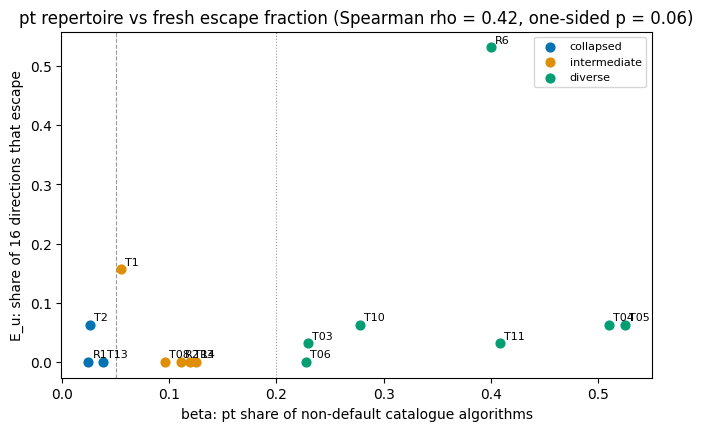

In [33]:
# demo: the aii-data-fig-gen house-style helpers are not part of the published repository (figures.py then falls back to
# plain matplotlib, HOUSE = False), and each figure is shown inline instead of saved to figures/*.pdf / *.png
HOUSE = False
PALETTE = ["#0173B2", "#DE8F05", "#029E73", "#D55E00", "#CC78BC", "#CA9161", "#FBAFE4", "#949494"]


def style() -> None:
    if HOUSE:
        apply_house_style()


def finish(fig, name: str) -> None:
    # demo: was the house-style layout fitters + fig.savefig(FIG_DIR / f"{name}.pdf"), fig.savefig(... .png) + plt.close(fig)
    plt.show()


def legend(ax, loc="best"):
    if HOUSE:
        place_legend(ax, loc=loc)
    else:
        ax.legend(loc=loc, fontsize=8)


def f1(c1, a1, esc) -> None:
    style()
    fig, ax = plt.subplots(figsize=(6.5, 4.2), layout="constrained")
    units = a1["units"]
    x = [a1["beta"][t] for t in units]
    y = [a1["E"][t] for t in units]
    cls = [c1["units"][t]["class"] for t in units]
    col = {"COLLAPSED": PALETTE[0], "INTERMEDIATE": PALETTE[1], "DIVERSE": PALETTE[2]}
    for c in ("COLLAPSED", "INTERMEDIATE", "DIVERSE"):
        xi = [a for a, k in zip(x, cls) if k == c]
        yi = [b for b, k in zip(y, cls) if k == c]
        if xi:
            ax.scatter(xi, yi, s=40, color=col[c], label=c.lower(), zorder=3)
    for t, a, b in zip(units, x, y):
        if HOUSE:
            place_point_label(ax, literal(t), (a, b))
        else:
            ax.annotate(t, (a, b), fontsize=8, xytext=(3, 3), textcoords="offset points")
    rho = a1["rho"]
    p = a1["p_one_sided_perm"]
    ax.set_title(f"pt repertoire vs fresh escape fraction (Spearman rho = {rho if rho is None else round(rho, 2)}, "
                 f"one-sided p = {p if p is None else round(p, 3)})")
    ax.set_xlabel("beta: pt share of non-default catalogue algorithms")
    ax.set_ylabel("E_u: share of 16 directions that escape")
    ax.axvline(0.05, color="0.6", lw=0.8, ls="--")
    ax.axvline(0.2, color="0.6", lw=0.8, ls=":")
    legend(ax)
    finish(fig, "fig1_beta_vs_escape")


f1(c1, a1, esc)

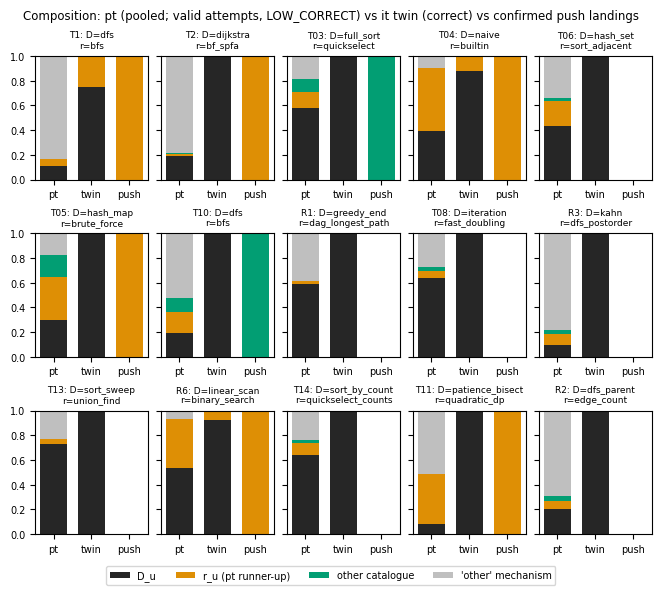

In [34]:
def f2(c1, esc) -> None:
    """Per task: share of D_u, r_u, other catalogue algorithms and 'other' in the pt primary composition (LOW_CORRECT:
    valid attempts), the it twin's correct programs and the correct off-default programs of confirmed escapes."""
    style()
    tasks = list(ALL_TASKS)
    fig, axes = plt.subplots(3, 5, figsize=(6.5, 5.8), layout="constrained", sharey=True)
    cats = ["D_u", "r_u (pt runner-up)", "other catalogue", "'other' mechanism"]
    cols = ["0.15", PALETTE[1], PALETTE[2], "0.75"]
    for ax, t in zip(axes.flat, tasks):
        u = c1["units"][t]
        cat, D, r = u["catalogue"], u["D"], u["r_u"]
        src = u[u["primary_source"]]
        pt_c = src["attempt_counts"] if u["low_correct"] else src["correct_counts"]
        pt_c = {k: v for k, v in pt_c.items() if k not in ("invalid", "disputed")}
        srcs = [pt_c, u["default"]["correct_counts"],
                (esc[t].get("landing") or {}).get("composition", {}) if esc[t].get("defaulted") else {}]
        bottom = np.zeros(3)
        for ci, cname in enumerate(cats):
            vals = []
            for sdict in srcs:
                tot = sum(v for k, v in sdict.items() if k in cat or k == "other")
                if cname == "D_u":
                    x = sdict.get(D, 0)
                elif cname.startswith("r_u"):
                    x = sdict.get(r, 0) if r else 0
                elif cname == "other catalogue":
                    x = sum(v for k, v in sdict.items() if k in cat and k not in (D, r))
                else:
                    x = sdict.get("other", 0)
                vals.append(x / tot if tot else 0.0)
            ax.bar(range(3), vals, bottom=bottom, color=cols[ci], width=0.7, label=cname if t == tasks[0] else None)
            bottom += np.array(vals)
        ax.set_xticks(range(3), ["pt", "twin", "push"], fontsize=7)
        ax.set_title(f"{t}: D={D}\nr={r}", fontsize=6.5)
        ax.tick_params(axis="y", labelsize=7)
    fig.legend(*axes.flat[0].get_legend_handles_labels(), loc="outside lower center", ncols=4, fontsize=7)
    fig.suptitle("Composition: pt (pooled; valid attempts, LOW_CORRECT) vs it twin (correct) vs confirmed push landings",
                 fontsize=8.5)
    plt.show()  # demo: was fig.savefig(FIG_DIR / "fig2_compositions.pdf"), fig.savefig(... .png, dpi=200), plt.close(fig)


f2(c1, esc)

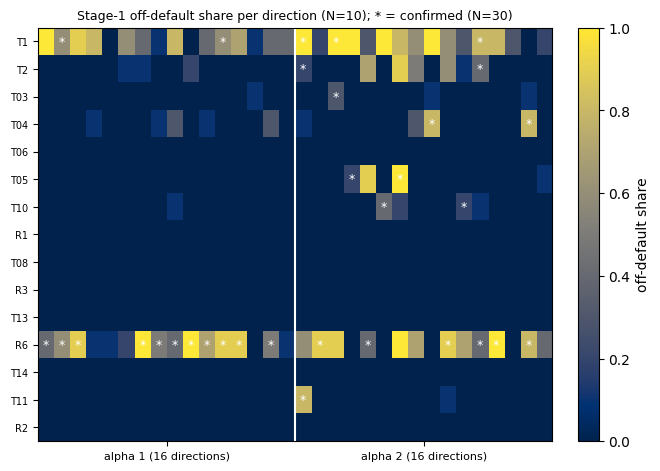

In [35]:
def f3(c1, esc) -> None:
    style()
    tasks = [t for t in ALL_TASKS if esc[t].get("defaulted")]
    cols = [f"{s}_a{int(a)}" for a in ALPHAS for s in DIR_SEEDS]
    M = np.array([[esc[t]["per_direction"].get(c, {}).get("off_cat") or 0.0 for c in cols] for t in tasks])
    fig, ax = plt.subplots(figsize=(6.5, 4.6), layout="constrained")
    im = ax.imshow(M, aspect="auto", cmap="cividis", vmin=0, vmax=1)
    for i, t in enumerate(tasks):
        for j, c in enumerate(cols):
            if esc[t]["per_direction"].get(c, {}).get("confirmed"):
                ax.text(j, i, "*", ha="center", va="center", color="white", fontsize=9)
    ax.set_yticks(range(len(tasks)), tasks, fontsize=7)
    ax.set_xticks([7.5, 23.5], ["alpha 1 (16 directions)", "alpha 2 (16 directions)"], fontsize=8)
    ax.axvline(15.5, color="white", lw=1.5)
    ax.grid(False)
    ax.set_title("Stage-1 off-default share per direction (N=10); * = confirmed (N=30)", fontsize=9)
    cb = fig.colorbar(im, ax=ax)
    cb.set_label("off-default share")
    plt.show()  # demo: was fig.savefig(FIG_DIR / "fig3_direction_heatmap.pdf"), fig.savefig(... .png, dpi=200), plt.close(fig)


f3(c1, esc)

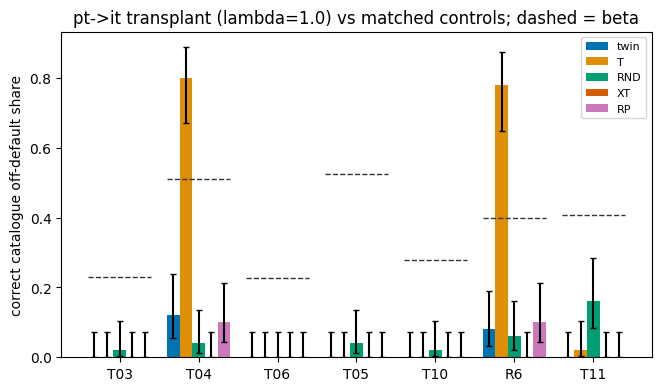

In [36]:
def f4(tp) -> None:
    if not tp or not tp.get("per_unit"):
        return
    style()
    units = list(tp["per_unit"])
    arms = ["twin", "T", "RND", "XT", "RP"]
    fig, ax = plt.subplots(figsize=(6.5, 3.8), layout="constrained")
    w = 0.16
    for i, a in enumerate(arms):
        vals, lo, hi = [], [], []
        for u in units:
            d = tp["per_unit"][u].get(a, {})
            s = d.get("s")
            ci = d.get("s_ci95") or [s, s]
            vals.append(s if s is not None else 0)
            lo.append(max(0.0, (s or 0) - (ci[0] if ci[0] is not None else 0)))
            hi.append(max(0.0, (ci[1] if ci[1] is not None else 0) - (s or 0)))
        ax.bar(np.arange(len(units)) + (i - 2) * w, vals, width=w, yerr=[lo, hi], capsize=2, label=a,
               color=PALETTE[i % len(PALETTE)])
    for j, u in enumerate(units):
        b = tp["per_unit"][u].get("beta")
        if b is not None:
            ax.plot([j - 2.5 * w, j + 2.5 * w], [b, b], color="0.2", ls="--", lw=1)
    ax.set_xticks(range(len(units)), units)
    ax.set_ylabel("correct catalogue off-default share")
    ax.set_title(f"pt->it transplant (lambda={tp['lambda'].get('lambda')}) vs matched controls; dashed = beta")
    legend(ax, "upper right")
    finish(fig, "fig4_transplant")


f4(tp)

## 11. Summary: recomputed vs reported

This table puts every headline number recomputed in this notebook next to the value the full run reported. The match tolerance depends on the Monte-Carlo sizes:
- **At the original sizes**, everything matches exactly, because the seeds and the order of the units are the same.
- **At smaller sizes**, the permutation p-value and the bootstrap rival comparisons drift within their Monte-Carlo error.

The plot shows each E-A2 event's mean log score under the three forecasts; higher is better.

quantity                                                      recomputed                      reported  match
E-A1  Spearman rho(beta, E_u)                                     0.4206                        0.4206  yes
E-A1  one-sided permutation p                                     0.0596                        0.0596  yes
E-A1  immovable share of collapsed units                          0.6667                        0.6667  yes
E-A1  rho(twin modal share, E_u)                                  0.6680                        0.6680  yes
E-A1  rho(novelty off-default, E_u)                               0.6398                        0.6398  yes
E-A1  beta ahead of every rival                                    False                         False  yes
E-A1  verdict                                               INCONCLUSIVE                  INCONCLUSIVE  yes
E-A2  events                                                           7                             7  yes
E-A2  hits (r_u = landing)

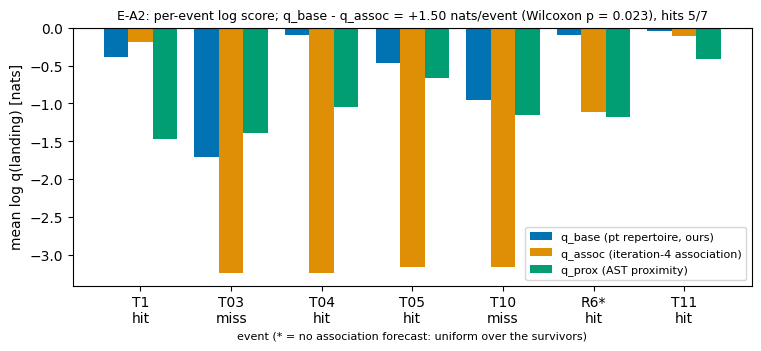

In [37]:
def _same(x, y, tol):
    if isinstance(x, (int, float)) and isinstance(y, (int, float)) and not isinstance(x, bool):
        return abs(x - y) <= tol
    return x == y


rv = rep["verdicts"]
r1, r2 = rep["e_a1"], rep["e_a2"]
tol_p = 3 * math.sqrt(0.06 * 0.94 / N_PERM) + 1e-9    # Monte-Carlo tolerance of the permutation p
summary = [
    ("E-A1  Spearman rho(beta, E_u)", a1["rho"], r1["rho"], 1e-9),
    ("E-A1  one-sided permutation p", a1["p_one_sided_perm"], r1["p_one_sided_perm"], tol_p),
    ("E-A1  immovable share of collapsed units", a1["immovable_frac_collapsed"], r1["immovable_frac_collapsed"], 1e-9),
    ("E-A1  rho(twin modal share, E_u)", a1["rivals"]["twin_modal_share"]["rho"], r1["rival_rho"]["twin_modal_share"], 1e-9),
    ("E-A1  rho(novelty off-default, E_u)", a1["rivals"]["novelty_off_cat"]["rho"], r1["rival_rho"]["novelty_off_cat"], 1e-9),
    ("E-A1  beta ahead of every rival", a1["ahead_of_every_rival"], r1["ahead_of_every_rival"], 0),
    ("E-A1  verdict", a1["verdict"], r1["verdict"], 0),
    ("E-A2  events", a2["n_events"], r2["n_events"], 0),
    ("E-A2  hits (r_u = landing)", a2["hits"], r2["hits"], 0),
    ("E-A2  exact Poisson-binomial p", a2["poisson_binomial_p"], r2["poisson_binomial_p"], 1e-12),
    ("E-A2  q_base - q_assoc (nats/event)", a2["mean_base_minus_assoc"], r2["mean_base_minus_assoc"], 1e-9),
    ("E-A2  q_base - q_prox (nats/event)", a2["mean_base_minus_prox"], r2["mean_base_minus_prox"], 1e-9),
    ("E-A2  Wilcoxon p (base vs assoc)", a2["wilcoxon_p_base_vs_assoc"], r2["wilcoxon_p_base_vs_assoc"], 1e-12),
    ("E-A2  verdict", a2["verdict"], r2["verdict"], 0),
    ("Transplant  share of S_T supporting", summ["share_supporting_of_valid"], rep["transplant_share_supporting_of_valid"], 1e-12),
    ("Transplant  verdict", verdicts["transplant"]["verdict"], rv["transplant"]["verdict"], 0),
    ("Escape  E_u of all 15 units", [esc[t]["E_u"] for t in ALL_TASKS], [rep["escape"][t]["E_u"] for t in ALL_TASKS], 0),
    ("Escape  landings", [esc[t]["landing"].get("landing") for t in ALL_TASKS],
     [rep["escape"][t]["landing"] for t in ALL_TASKS], 0),
]
print(f"{'quantity':<42}{'recomputed':>30}{'reported':>30}  match")
for name, x, y, tol in summary:
    show = (lambda v: f"{v:.4f}" if isinstance(v, float) else ("(list)" if isinstance(v, list) else str(v)))
    print(f"{name:<42}{show(x):>30}{show(y):>30}  {'yes' if _same(x, y, tol) else 'NO'}")
print(f"\n{sum(_same(x, y, tol) for _, x, y, tol in summary)}/{len(summary)} match "
      f"(N_PERM={N_PERM}, N_BOOT={N_BOOT}, N_PERM_SENS={N_PERM_SENS}, HILL_SUBSAMPLES={HILL_SUBSAMPLES})")

# --- E-A2 log scores per event (higher = the forecast put more mass on where the programs actually landed) ---
fig, ax = plt.subplots(figsize=(7.5, 3.4), layout="constrained")
units_ev = [r["unit"] for r in a2["log_scores"]]
xs = np.arange(len(units_ev))
for i, (k, lab) in enumerate((("q_base", "q_base (pt repertoire, ours)"), ("q_assoc", "q_assoc (iteration-4 association)"),
                              ("q_prox", "q_prox (AST proximity)"))):
    ax.bar(xs + (i - 1) * 0.27, [r[k] for r in a2["log_scores"]], width=0.27, label=lab, color=PALETTE[i])
ax.set_xticks(xs, [f"{u}{'' if r['q_assoc_defined'] else '*'}\n{'hit' if e['r_u'] == e['landing'] else 'miss'}"
                   for u, e, r in zip(units_ev, a2["events"], a2["log_scores"])])
ax.set_xlabel("event (* = no association forecast: uniform over the survivors)", fontsize=8)
ax.set_ylabel("mean log q(landing) [nats]")
ax.set_title(f"E-A2: per-event log score; q_base - q_assoc = {a2['mean_base_minus_assoc']:+.2f} nats/event "
             f"(Wilcoxon p = {a2['wilcoxon_p_base_vs_assoc']:.3f}), hits {a2['hits']}/{a2['n_events']}", fontsize=9)
ax.axhline(0, color="0.3", lw=0.8)
ax.legend(fontsize=8, loc="lower right")
plt.show()